# Assignment 2 — Exploratory Data Analysis
## Student ID: 23L-0997

---

## Published Dataset Links and Versions

| Dataset | GitHub / Kaggle Link | Version / Tag |
|---|---|---|
| Netflix (cleaned) | https://github.com/SheikhFareed99/Data-cleaning-eda/blob/v1.0/23L_0997_A2_netflix_cleaned.csv | v1.0 |
| Supermarket Sales (cleaned) | https://github.com/SheikhFareed99/Data-cleaning-eda/blob/v1.0/23L_0997_A2_supermarket_cleaned.csv | v1.0 |

> **Sources:** Netflix: Kaggle `shivamb/netflix-shows`; Supermarket: instructor-provided `supermarket_Sales.csv`.

---

## Part B — Supermarket Sales Dataset

Full EDA workflow: **Understand → Inspect → Clean → Explore → Interpret**.

# Part A — Netflix Movies and TV Shows Dataset

**Original source:** [Kaggle — Netflix Shows (Shivam Bansal)](https://www.kaggle.com/datasets/shivamb/netflix-shows)  
**Cleaned dataset publication:** `https://github.com/SheikhFareed99/Data-cleaning-eda` — version `v1.0`

This section follows Understand → Inspect → Clean → Explore → Interpret. A row is one Netflix catalogue title (a Movie or TV Show).

## A1. Dataset Understanding (2 Marks)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

netflix = pd.read_csv('netflix-source/netflix_titles.csv')
print(f"Shape: {netflix.shape[0]:,} rows × {netflix.shape[1]} columns")
display(netflix.head())
print(netflix.dtypes)

Shape: 8,807 rows × 12 columns


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object


### Variable role table

| Columns | Type | Role note |
|---|---|---|
| `show_id` | Identifier | Unique catalogue identifier; not an analytical feature |
| `type`, `rating` | Categorical | Content format and maturity classification |
| `country`, `listed_in`, `cast` | Multi-valued categorical | Comma-separated countries, genres, and people |
| `title`, `description`, `director` | Text | Title metadata; director may be analysed after grouping |
| `date_added` | Date | When a title entered the catalogue |
| `release_year` | Numerical/discrete | Original release year |
| `duration` | Mixed text | Movie minutes or TV seasons; split during cleaning |

## A2. Data Quality Assessment (4 Marks)

In [2]:
print('Missing values:')
display(netflix.isna().sum().sort_values(ascending=False).to_frame('missing'))
print('\nFull-row duplicates:', netflix.duplicated().sum())
print('Duplicate show_id values:', netflix.duplicated('show_id').sum())
print('\nData types:')
print(netflix.dtypes)
for col in ['type', 'rating']:
    print(f"\n{col} values:", sorted(netflix[col].dropna().astype(str).str.strip().unique()))
print('\nDuration by type:')
display(netflix.groupby('type')['duration'].agg(['count', 'nunique']).reset_index())
print('\nPotential non-rating labels:')
print(netflix.loc[~netflix['rating'].isin(['G','NC-17','NR','PG','PG-13','R','TV-14','TV-G','TV-MA','TV-PG','TV-Y','TV-Y7','TV-Y7-FV','UR']), ['title','rating','duration']].head(20))
print('\nRelease-year IQR fences:')
q1, q3 = netflix.release_year.quantile([.25,.75]); iqr=q3-q1
print(q1 - 1.5*iqr, q3 + 1.5*iqr, '| outside:', ((netflix.release_year < q1-1.5*iqr) | (netflix.release_year > q3+1.5*iqr)).sum())

Missing values:


,missing
director,2634
country,831
cast,825
date_added,10
rating,4
duration,3
show_id,0
type,0
title,0
release_year,0



Full-row duplicates: 0
Duplicate show_id values: 0

Data types:
show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

type values: ['Movie', 'TV Show']

rating values: ['66 min', '74 min', '84 min', 'G', 'NC-17', 'NR', 'PG', 'PG-13', 'R', 'TV-14', 'TV-G', 'TV-MA', 'TV-PG', 'TV-Y', 'TV-Y7', 'TV-Y7-FV', 'UR']

Duration by type:


,type,count,nunique
0,Movie,6128,205
1,TV Show,2676,15



Potential non-rating labels:
                                                  title  rating  duration
5541                                    Louis C.K. 2017  74 min       NaN
5794                              Louis C.K.: Hilarious  84 min       NaN
5813               Louis C.K.: Live at the Comedy Store  66 min       NaN
5989  13TH: A Conversation with Oprah Winfrey & Ava ...     NaN    37 min
6827                  Gargantia on the Verdurous Planet     NaN  1 Season
7312                                       Little Lunch     NaN  1 Season
7537                               My Honor Was Loyalty     NaN   115 min

Release-year IQR fences:
2004.0 2028.0 | outside: 719


## A3. Data Cleaning (4 Marks)

In [3]:
clean = netflix.copy()
# Some known records store a duration (for example "74 min") in rating; repair it before parsing.
valid_ratings = {'G','NC-17','NR','PG','PG-13','R','TV-14','TV-G','TV-MA','TV-PG','TV-Y','TV-Y7','TV-Y7-FV','UR'}
misplaced_duration = ~clean['rating'].isin(valid_ratings) & clean['rating'].notna()
clean.loc[misplaced_duration, 'duration'] = clean.loc[misplaced_duration, 'rating']
clean.loc[misplaced_duration, 'rating'] = np.nan

# Standardize strings and make missing metadata explicit where it is a category.
for col in ['director', 'cast', 'country', 'listed_in']:
    clean[col] = clean[col].fillna('Unknown').astype(str).str.strip()
clean['rating'] = clean['rating'].fillna('Unknown').astype(str).str.strip()
clean['date_added'] = pd.to_datetime(clean['date_added'], errors='coerce')
clean['year_added'] = clean['date_added'].dt.year.astype('Int64')
clean['month_added'] = clean['date_added'].dt.month.astype('Int64')
clean['country_count'] = clean['country'].replace('Unknown', np.nan).str.count(',').add(1).fillna(0).astype(int)
clean['genre_count'] = clean['listed_in'].replace('Unknown', np.nan).str.count(',').add(1).fillna(0).astype(int)
clean['movie_duration_min'] = np.where(clean['type'].eq('Movie'), clean['duration'].str.extract(r'(\d+)')[0], np.nan)
clean['tv_seasons'] = np.where(clean['type'].eq('TV Show'), clean['duration'].str.extract(r'(\d+)')[0], np.nan)
clean['movie_duration_min'] = pd.to_numeric(clean['movie_duration_min'], errors='coerce')
clean['tv_seasons'] = pd.to_numeric(clean['tv_seasons'], errors='coerce')
clean['release_to_added_gap'] = clean['year_added'] - clean['release_year']
clean.to_csv('23L_0997_A2_netflix_cleaned.csv', index=False)
print('Repaired misplaced rating/duration records:', misplaced_duration.sum())
print('Saved 23L_0997_A2_netflix_cleaned.csv:', clean.shape)
display(clean.head())

Repaired misplaced rating/duration records: 3
Saved 23L_0997_A2_netflix_cleaned.csv: (8807, 19)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added,country_count,genre_count,movie_duration_min,tv_seasons,release_to_added_gap
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021,9,1,1,90.0,NaN,1
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,9,1,3,NaN,2.0,0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021,9,0,3,NaN,1.0,0
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021,9,0,2,NaN,1.0,0
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021,9,1,3,NaN,2.0,0


### Cleaning decision log

| Problem | Detection | Decision | Justification |
|---|---|---|---|
| Missing director/cast/country | `isna().sum()` | Use `Unknown` | Missingness is meaningful metadata and rows should be retained |
| Missing date added/rating | Missing-count output | Parse date; use `Unknown` for rating; retain unavailable dates | Avoid unsupported imputation |
| Duration in `rating` | Invalid rating labels | Move value to duration and set rating missing | Corrects a known field-shift issue without dropping titles |
| Mixed duration units | Duration by content type | Create movie minutes and TV seasons separately | These measures are not comparable |
| Old release years flagged by IQR | IQR result | Retain | Genuine catalogue history, not data errors |

## A4–A6. Univariate, Bivariate, and Multivariate EDA (9 Marks)

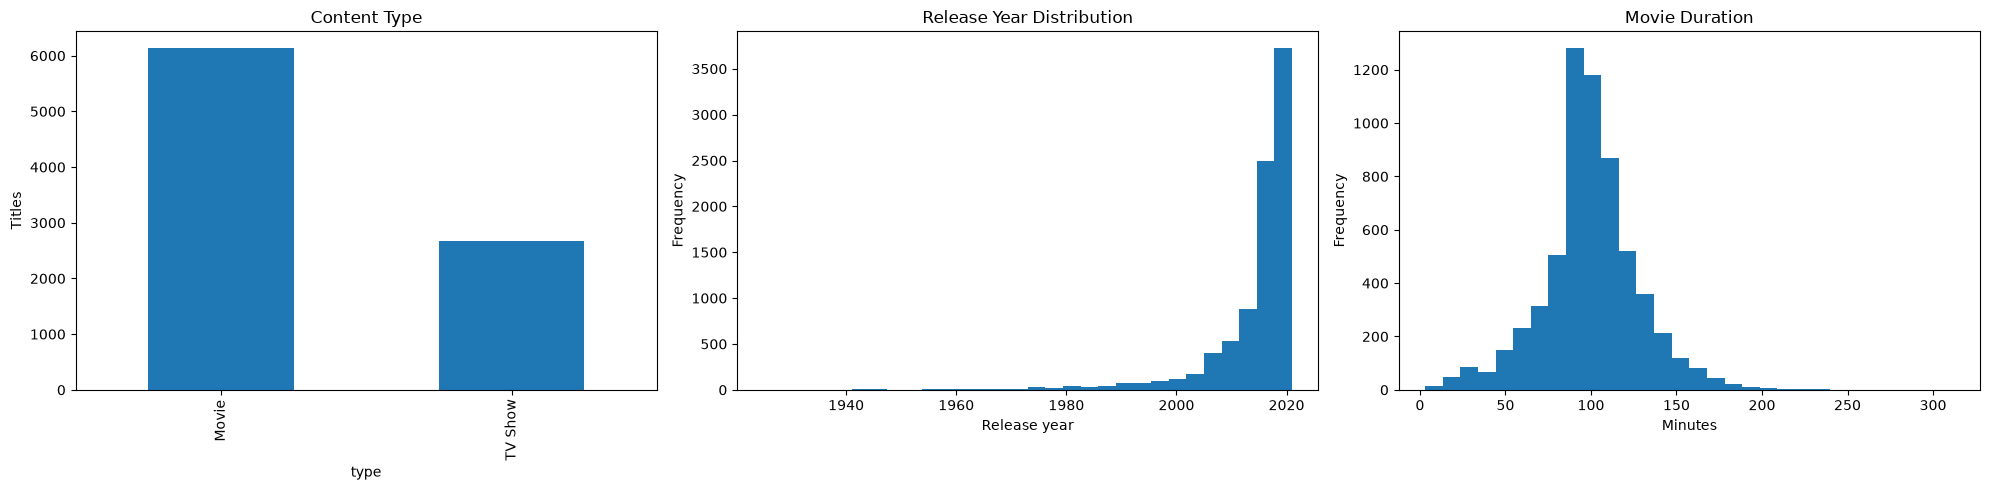

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
release_year,8807.0,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
country_count,8807.0,1.137618,0.759317,0.0,1.0,1.0,1.0,12.0
genre_count,8807.0,2.194050,0.784341,1.0,2.0,2.0,3.0,3.0
movie_duration_min,6131.0,99.564998,28.289504,3.0,87.0,98.0,114.0,312.0
tv_seasons,2676.0,1.764948,1.582752,1.0,1.0,1.0,2.0,17.0


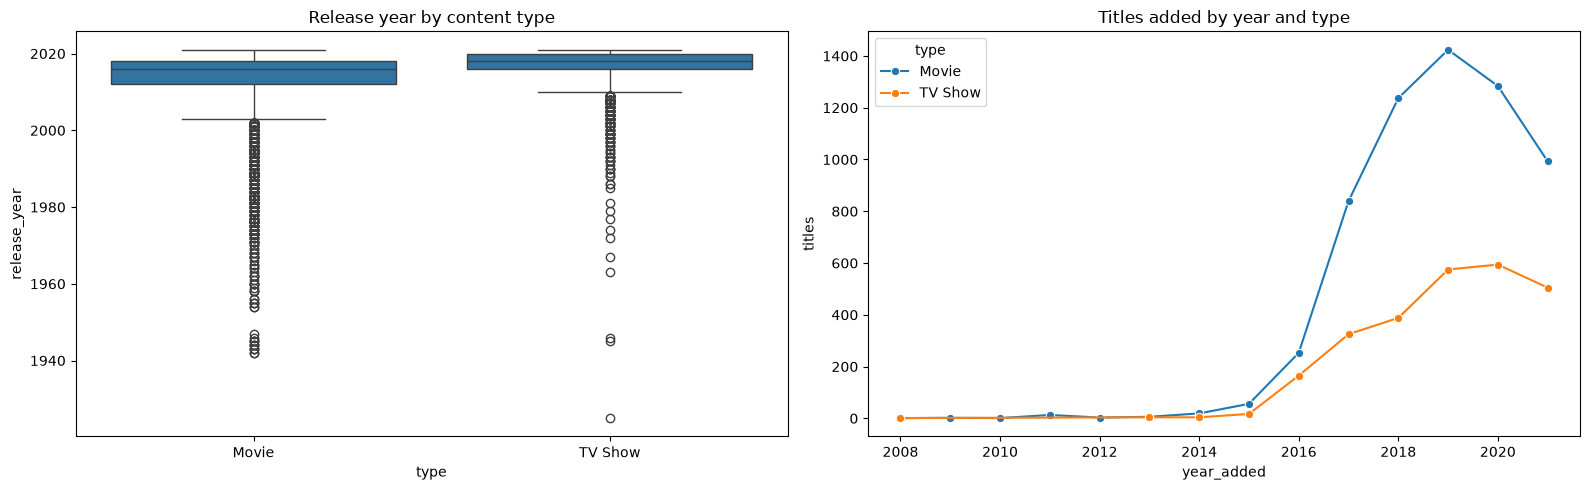

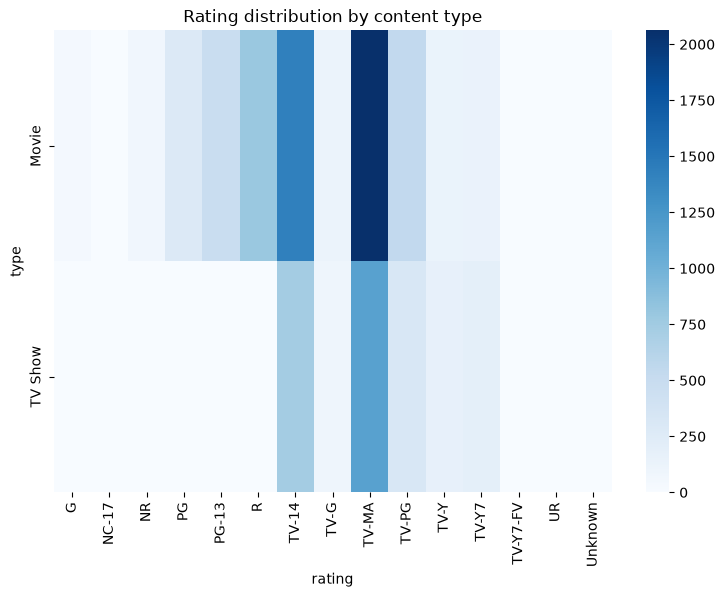

Correlation of meaningful numerical features:


,release_year,country_count,genre_count,movie_duration_min,tv_seasons,release_to_added_gap
release_year,1.00,-0.07,-0.04,-0.21,-0.09,-0.98
country_count,-0.07,1.00,0.01,0.09,0.12,0.06
genre_count,-0.04,0.01,1.00,0.41,-0.08,0.05
movie_duration_min,-0.21,0.09,0.41,1.00,NaN,0.22
tv_seasons,-0.09,0.12,-0.08,NaN,1.00,0.06
release_to_added_gap,-0.98,0.06,0.05,0.22,0.06,1.00


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(20,5))
clean['type'].value_counts().plot.bar(ax=ax[0], title='Content Type'); ax[0].set_ylabel('Titles')
clean['release_year'].plot.hist(bins=30, ax=ax[1], title='Release Year Distribution'); ax[1].set_xlabel('Release year')
clean.loc[clean.type.eq('Movie'), 'movie_duration_min'].plot.hist(bins=30, ax=ax[2], title='Movie Duration'); ax[2].set_xlabel('Minutes')
plt.tight_layout(); plt.show()
print('Numerical summary:')
display(clean[['release_year','country_count','genre_count','movie_duration_min','tv_seasons']].describe().T)

fig, ax = plt.subplots(1, 2, figsize=(16,5))
sns.boxplot(data=clean, x='type', y='release_year', ax=ax[0]); ax[0].set_title('Release year by content type')
annual = clean.groupby(['year_added','type']).size().reset_index(name='titles')
sns.lineplot(data=annual, x='year_added', y='titles', hue='type', marker='o', ax=ax[1]); ax[1].set_title('Titles added by year and type')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9,6))
pivot = clean.pivot_table(index='type', columns='rating', values='show_id', aggfunc='count', fill_value=0)
sns.heatmap(pivot, cmap='Blues', ax=ax); ax.set_title('Rating distribution by content type'); plt.show()
print('Correlation of meaningful numerical features:')
display(clean[['release_year','country_count','genre_count','movie_duration_min','tv_seasons','release_to_added_gap']].corr(numeric_only=True).round(2))

## A7. Netflix-Specific Analytical Questions (2 Marks)

In [5]:
# 1–5: reproducible tables used to answer the required analytical questions
print('1. Content mix by release year and year added')
display(clean.groupby(['year_added','type']).size().unstack(fill_value=0).tail(12))
print('\n2. Release-to-added gap (years)')
display(clean['release_to_added_gap'].describe())
print('\n3. Top countries and genres')
top_countries = clean.loc[clean.country.ne('Unknown'),'country'].str.split(', ').explode().value_counts().head(10)
top_genres = clean.loc[clean.listed_in.ne('Unknown'),'listed_in'].str.split(', ').explode().value_counts().head(10)
display(top_countries.to_frame('titles')); display(top_genres.to_frame('titles'))
print('\n4. Maturity ratings by type')
display(pd.crosstab(clean['rating'], clean['type']).sort_values(['Movie','TV Show'], ascending=False).head(12))
print('\n5. Movie minutes and TV seasons')
display(clean.groupby('type')[['movie_duration_min','tv_seasons']].describe())

1. Content mix by release year and year added


type,Movie,TV Show
year_added,,
2010,1,0
2011,13,0
2012,3,0
2013,6,4
2014,19,4
2015,56,17
2016,253,165
2017,839,325
2018,1237,388



2. Release-to-added gap (years)


count      8709.0
mean     4.690894
std      8.792208
min          -3.0
25%           0.0
50%           1.0
75%           5.0
max          93.0
Name: release_to_added_gap, dtype: Float64


3. Top countries and genres


...

,titles
listed_in,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641



4. Maturity ratings by type


type,Movie,TV Show
rating,,
TV-MA,2062,1145
TV-14,1427,733
R,797,2
TV-PG,540,323
PG-13,490,0
PG,287,0
TV-Y7,139,195
TV-Y,131,176
TV-G,126,94



5. Movie minutes and TV seasons


movie_duration_min                                                \
                     count       mean        std  min   25%   50%    75%   
type                                                                       
Movie               6131.0  99.564998  28.289504  3.0  87.0  98.0  114.0   
TV Show                0.0        NaN        NaN  NaN   NaN   NaN    NaN   

               tv_seasons                                                
           max      count      mean       std  min  25%  50%  75%   max  
type                                                                     
Movie    312.0        0.0       NaN       NaN  NaN  NaN  NaN  NaN   NaN  
TV Show    NaN     2676.0  1.764948  1.582752  1.0  1.0  1.0  2.0  17.0

## A8. Netflix Insights and Handoff (2 Marks)

1. **Movies dominate the catalogue**, while the year-added table shows whether TV-show additions gained share in later years.
2. **The release-to-added gap is often positive**, so the catalogue includes both recent releases and older library content; this does not identify licensing reasons.
3. **Country and genre rankings must split comma-separated values**, otherwise co-productions and multi-genre titles are undercounted.
4. **Ratings differ by content type**, so maturity classifications should be treated as categorical rather than ordinal.
5. **Movie minutes and TV seasons are distinct measures** and were analysed separately; unusually short/long genuine titles were retained.

### Assignment 3 handoff (≤150 words)
Useful variables include content `type`, `release_year`, `year_added`, `rating`, split countries/genres, and the derived duration measures. `show_id` is an identifier and `title`, `description`, and free-text names should not be used as ordinary numerical features. `duration` must not be modelled directly because its unit differs by type; use `movie_duration_min` or `tv_seasons` after filtering by type. `country`, `cast`, and `listed_in` are multi-valued and require splitting before frequency-based analysis. Missing metadata was represented as `Unknown`, and invalid ratings containing durations were repaired; both decisions should be kept consistent in Assignment 3.

In [6]:
# ─── Imports & Global Settings ───────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': '#0f0f1a',
    'axes.facecolor':   '#1a1a2e',
    'axes.edgecolor':   '#444466',
    'axes.labelcolor':  '#c8c8e8',
    'xtick.color':      '#c8c8e8',
    'ytick.color':      '#c8c8e8',
    'text.color':       '#c8c8e8',
    'grid.color':       '#2a2a4a',
    'grid.linestyle':   '--',
    'grid.alpha':       0.5,
    'font.family':      'DejaVu Sans',
    'axes.titlesize':   14,
    'axes.labelsize':   12,
    'legend.facecolor': '#16213e',
    'legend.edgecolor': '#444466',
})
PALETTE = ['#7b68ee', '#48d1cc', '#ff6b9d', '#ffd700', '#00fa9a', '#ff8c00']
sns.set_palette(PALETTE)
print('Libraries loaded successfully.')

Libraries loaded successfully.


---
## B1. Dataset Understanding (2 Marks)

In [7]:
# ─── B1.1 Load dataset ───────────────────────────────────────────────────────
df = pd.read_csv('supermarket_Sales.csv')
print(f'Shape: {df.shape[0]} rows x {df.shape[1]} columns')
print('\nFirst 5 records:')
df.head()

Shape: 1000 rows x 17 columns

First 5 records:


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [8]:
# ─── B1.2 Data types & basic info ───────────────────────────────────────────
print('Column data types:')
print(df.dtypes)
print('\nDataset info:')
df.info()

Column data types:
Invoice ID                            str
Branch                                str
City                                  str
Customer type                         str
Gender                                str
Product line                          str
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Date                                  str
Time                                  str
Payment                               str
Cost of goods sold                float64
Gross margin percentage           float64
Gross income                      float64
Customer stratification rating    float64
dtype: object

Dataset info:


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Invoice ID                      1000 non-null   str    
 1   Branch                          1000 non-null   str    
 2   City                            1000 non-null   str    
 3   Customer type                   1000 non-null   str    
 4   Gender                          1000 non-null   str    
 5   Product line                    1000 non-null   str    
 6   Unit price                      1000 non-null   float64
 7   Quantity                        1000 non-null   int64  
 8   Tax 5%                          1000 non-null   float64
 9   Total                           1000 non-null   float64
 10  Date                            1000 non-null   str    
 11  Time                            1000 non-null   str    
 12  Payment                         1000 non-null 

### What a single row represents

> **A single row represents one supermarket transaction**: a customer's purchase at one of three branch cities (Yangon, Mandalay, Naypyitaw), recording the product category bought, the quantities, unit price, taxes, total amount paid, payment method, and the customer's satisfaction rating.

In [9]:
# ─── B1.3 Variable Role Table ────────────────────────────────────────────────
role_table = pd.DataFrame([
    ['Invoice ID',                 'Identifier',                'Unique transaction ID — not an analytical feature'],
    ['Branch',                     'Categorical',               'Branch letter (A/B/C); maps 1-to-1 with City'],
    ['City',                       'Categorical',               'City of the branch; redundant with Branch'],
    ['Customer type',              'Categorical (binary)',       'Member vs Normal customer'],
    ['Gender',                     'Categorical (binary)',       'Male / Female'],
    ['Product line',               'Categorical',               'One of 6 product categories — key grouping variable'],
    ['Unit price',                 'Numerical (continuous)',     'Price per unit in local currency'],
    ['Quantity',                   'Numerical (discrete)',       'Units purchased (1-10)'],
    ['Tax 5%',                     'Numerical (continuous)',     '5% of COGS; derivable: UnitPrice x Qty x 0.05'],
    ['Total',                      'Numerical (continuous)',     'COGS + Tax; derivable — key revenue outcome'],
    ['Date',                       'Date',                      'Transaction date (Jan-Mar 2019); stored as string initially'],
    ['Time',                       'Time',                      'Transaction time HH:MM; stored as string initially'],
    ['Payment',                    'Categorical',               'Ewallet / Cash / Credit card'],
    ['Cost of goods sold',         'Numerical (continuous)',     'COGS = UnitPrice x Qty; derivable'],
    ['Gross margin percentage',    'Numerical (constant)',       'Always 4.761904762% — not analytically useful'],
    ['Gross income',               'Numerical (continuous)',     'Same as Tax 5% — redundant'],
    ['Customer stratification rating', 'Numerical (continuous)', 'Customer satisfaction score (1-10) — key outcome variable'],
], columns=['Column', 'Type', 'Role Note'])
print('Variable Role Table:')
role_table

Variable Role Table:


,Column,Type,Role Note
0,Invoice ID,Identifier,Unique transaction ID — not an analytical feature
1,Branch,Categorical,Branch letter (A/B/C); maps 1-to-1 with City
2,City,Categorical,City of the branch; redundant with Branch
3,Customer type,Categorical (binary),Member vs Normal customer
4,Gender,Categorical (binary),Male / Female
5,Product line,Categorical,One of 6 product categories — key grouping var...
6,Unit price,Numerical (continuous),Price per unit in local currency
7,Quantity,Numerical (discrete),Units purchased (1-10)
8,Tax 5%,Numerical (continuous),5% of COGS; derivable: UnitPrice x Qty x 0.05
9,Total,Numerical (continuous),COGS + Tax; derivable — key revenue outcome


---
## B2. Data Quality Assessment (4 Marks)

In [10]:
# ─── B2.1 Missing Values ─────────────────────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
total_missing = missing_df['Missing Count'].sum()
if total_missing == 0:
    print('NONE FOUND — no missing values in any column.')
else:
    print(missing_df[missing_df['Missing Count'] > 0])

NONE FOUND — no missing values in any column.


In [11]:
# ─── B2.2 Duplicate Records ──────────────────────────────────────────────────
full_dups = df.duplicated().sum()
invoice_dups = df.duplicated(subset='Invoice ID').sum()
print(f'Full-row duplicates     : {full_dups}')
print(f'Invoice ID duplicates   : {invoice_dups}')
print(f'Total unique Invoice IDs: {df["Invoice ID"].nunique()}')
if full_dups == 0 and invoice_dups == 0:
    print('\nConclusion: NO duplicates — each row is a unique transaction.')

Full-row duplicates     : 0
Invoice ID duplicates   : 0
Total unique Invoice IDs: 1000

Conclusion: NO duplicates — each row is a unique transaction.


In [12]:
# ─── B2.3 Incorrect Data Types ───────────────────────────────────────────────
print('Current dtypes:')
print(df.dtypes)
print('\nDate sample:', df['Date'].head(3).tolist())
print('Time sample:', df['Time'].head(3).tolist())
print('\nIssue: Date and Time are object (string) — must be converted to datetime/time.')

Current dtypes:
Invoice ID                            str
Branch                                str
City                                  str
Customer type                         str
Gender                                str
Product line                          str
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Date                                  str
Time                                  str
Payment                               str
Cost of goods sold                float64
Gross margin percentage           float64
Gross income                      float64
Customer stratification rating    float64
dtype: object

Date sample: ['1/5/2019', '3/8/2019', '3/3/2019']
Time sample: ['13:08', '10:29', '13:23']

Issue: Date and Time are object (string) — must be converted to datetime/time.


In [13]:
# ─── B2.4 Inconsistent Categorical Values ────────────────────────────────────
cat_cols = ['Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Payment']
for col in cat_cols:
    print(f'{col:30s}: {sorted(df[col].unique())}')
print('\nBranch-City mapping:')
print(df.groupby('Branch')['City'].unique())
print('\nConclusion: All categories are consistent — correct casing, no whitespace issues, Branch-City is 1-to-1.')

Branch                        : ['A', 'B', 'C']
City                          : ['Mandalay', 'Naypyitaw', 'Yangon']
Customer type                 : ['Member', 'Normal']
Gender                        : ['Female', 'Male']
Product line                  : ['Electronic accessories', 'Fashion accessories', 'Food and beverages', 'Health and beauty', 'Home and lifestyle', 'Sports and travel']
Payment                       : ['Cash', 'Credit card', 'Ewallet']

Branch-City mapping:
Branch
A       [Yangon]
B     [Mandalay]
C    [Naypyitaw]
Name: City, dtype: object

Conclusion: All categories are consistent — correct casing, no whitespace issues, Branch-City is 1-to-1.


In [14]:
# ─── B2.5 Suspicious / Invalid Values ───────────────────────────────────────
num_cols = ['Unit price', 'Quantity', 'Tax 5%', 'Total',
            'Cost of goods sold', 'Gross margin percentage',
            'Gross income', 'Customer stratification rating']
print(df[num_cols].describe().round(4))
print('\nGross margin % unique values:', df['Gross margin percentage'].unique())
rating = df['Customer stratification rating']
print(f'Rating range: {rating.min()} to {rating.max()}')
oor = df[(rating < 1) | (rating > 10)]
print(f'Out-of-range ratings: {len(oor)}')

       Unit price   Quantity     Tax 5%      Total  Cost of goods sold  \
count   1000.0000  1000.0000  1000.0000  1000.0000           1000.0000   
mean      55.6721     5.5100    15.3794   322.9667            307.5874   
std       26.4946     2.9234    11.7088   245.8853            234.1765   
min       10.0800     1.0000     0.5085    10.6785             10.1700   
25%       32.8750     3.0000     5.9249   124.4224            118.4975   
50%       55.2300     5.0000    12.0880   253.8480            241.7600   
75%       77.9350     8.0000    22.4453   471.3502            448.9050   
max       99.9600    10.0000    49.6500  1042.6500            993.0000   

       Gross margin percentage  Gross income  Customer stratification rating  
count                1000.0000     1000.0000                       1000.0000  
mean                    4.7619       15.3794                          6.9727  
std                     0.0000       11.7088                          1.7186  
min              


Gross margin % unique values: [4.76190476]
Rating range: 4.0 to 10.0
Out-of-range ratings: 0


In [15]:
# ─── B2.5b Mathematical Consistency Check ───────────────────────────────────
tax_ok   = (df['Unit price'] * df['Quantity'] * 0.05).round(4)
tax_mis  = (tax_ok != df['Tax 5%'].round(4)).sum()
tot_ok   = (df['Unit price'] * df['Quantity'] * 1.05).round(4)
tot_mis  = (tot_ok != df['Total'].round(4)).sum()
cogs_ok  = (df['Unit price'] * df['Quantity']).round(4)
cogs_mis = (cogs_ok != df['Cost of goods sold'].round(4)).sum()
gi_mis   = (df['Tax 5%'].round(4) != df['Gross income'].round(4)).sum()
print(f'Tax 5% recomputation mismatches    : {tax_mis}')
print(f'Total recomputation mismatches     : {tot_mis}')
print(f'COGS recomputation mismatches      : {cogs_mis}')
print(f'Gross income = Tax 5% mismatches   : {gi_mis}')
print('\nConclusion: All numerical columns are internally consistent — mathematically verified.')

Tax 5% recomputation mismatches    : 0
Total recomputation mismatches     : 0
COGS recomputation mismatches      : 0
Gross income = Tax 5% mismatches   : 0

Conclusion: All numerical columns are internally consistent — mathematically verified.


In [16]:
# ─── B2.6 Outlier Detection (IQR Method) ─────────────────────────────────────
key_num = ['Unit price', 'Quantity', 'Total', 'Customer stratification rating']
rows = []
for col in key_num:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append({'Column': col, 'Q1': round(Q1,2), 'Q3': round(Q3,2),
                 'Lower fence': round(lo,2), 'Upper fence': round(hi,2),
                 'Outlier count': n_out})
pd.DataFrame(rows).set_index('Column')

,Q1,Q3,Lower fence,Upper fence,Outlier count
Column,,,,,
Unit price,32.88,77.94,-34.72,145.52,0
Quantity,3.00,8.00,-4.50,15.50,0
Total,124.42,471.35,-395.97,991.74,9
Customer stratification rating,5.50,8.50,1.00,13.00,0


### Data Quality Summary

| Issue | Finding |
|---|---|
| Missing values | **None** — 0 missing cells across all 17 columns |
| Duplicates | **None** — all 1,000 Invoice IDs are unique |
| Incorrect data types | **Date** and **Time** stored as `object`; need conversion |
| Inconsistent categoricals | **None** — all categories are clean and consistently cased |
| Branch–City consistency | **Perfect** — A→Yangon, B→Mandalay, C→Naypyitaw |
| Suspicious values | **None** — numerical ranges plausible; rating 1–10 verified |
| Gross margin percentage | **Constant** (4.761904762%) — not analytically useful |
| Mathematical consistency | **Verified** — Tax, Total, COGS, Gross income all recompute exactly |
| Outliers | **None** via IQR for key analytical variables |

---
## B3. Data Cleaning (4 Marks)

In [17]:
# ─── B3 Type Conversions ─────────────────────────────────────────────────────
df_clean = df.copy()

# 1. Convert Date from string to datetime
df_clean['Date'] = pd.to_datetime(df_clean['Date'], format='%m/%d/%Y')
print('Date dtype after:', df_clean['Date'].dtype)
print('Date range:', df_clean['Date'].min().date(), '->', df_clean['Date'].max().date())

# 2. Convert Time from string to time object
df_clean['Time'] = pd.to_datetime(df_clean['Time'], format='%H:%M').dt.time
print('Time sample:', df_clean['Time'].head(3).tolist())

Date dtype after: datetime64[us]
Date range: 2019-01-01 -> 2019-03-30
Time sample: [datetime.time(13, 8), datetime.time(10, 29), datetime.time(13, 23)]


In [18]:
# ─── B3 Derived Variables ────────────────────────────────────────────────────

# Hour: captures time-of-day patterns
df_clean['Hour'] = pd.to_datetime(df['Time'], format='%H:%M').dt.hour

# Weekday: Monday=0, Sunday=6
df_clean['Weekday'] = df_clean['Date'].dt.day_name()
df_clean['Weekday_num'] = df_clean['Date'].dt.dayofweek

# Month name and number
df_clean['Month'] = df_clean['Date'].dt.month_name()
df_clean['Month_num'] = df_clean['Date'].dt.month

# Day of month
df_clean['Day'] = df_clean['Date'].dt.day

# Time of Day bucket
def time_of_day(h):
    if 10 <= h < 13:  return 'Morning'
    elif 13 <= h < 17: return 'Afternoon'
    else: return 'Evening'

df_clean['Time_of_day'] = df_clean['Hour'].apply(time_of_day)

print('Derived columns added: Hour, Weekday, Month, Day, Time_of_day')
print(f'Dataset shape: {df_clean.shape}')
df_clean[['Date', 'Time', 'Hour', 'Weekday', 'Month', 'Time_of_day']].head()

Derived columns added: Hour, Weekday, Month, Day, Time_of_day
Dataset shape: (1000, 24)


,Date,Time,Hour,Weekday,Month,Time_of_day
0,2019-01-05,13:08:00,13,Saturday,January,Afternoon
1,2019-03-08,10:29:00,10,Friday,March,Morning
2,2019-03-03,13:23:00,13,Sunday,March,Afternoon
3,2019-01-27,20:33:00,20,Sunday,January,Evening
4,2019-02-08,10:37:00,10,Friday,February,Morning


In [19]:
# ─── B3 Save Cleaned Dataset ─────────────────────────────────────────────────
df_clean.to_csv('23L_0997_A2_supermarket_cleaned.csv', index=False)
print('Saved: 23L_0997_A2_supermarket_cleaned.csv')
print(f'Final shape: {df_clean.shape[0]} rows x {df_clean.shape[1]} columns')

Saved: 23L_0997_A2_supermarket_cleaned.csv
Final shape: 1000 rows x 24 columns


### B3. Cleaning Decision Log

| Problem | Detection | Decision | Justification |
|---|---|---|---|
| **Date stored as string** | `df.dtypes` shows `object` | Convert to `datetime64` | Enables month/weekday/day extraction |
| **Time stored as string** | `df.dtypes` shows `object` | Convert to `time` object | Enables hour extraction |
| **No missing values** | `isnull().sum()` all zero | No action needed | Data is complete |
| **No duplicates** | `duplicated()` = 0 | No action needed | All Invoice IDs unique |
| **Gross margin % constant** | `unique()` → one value | Retain; flagged as non-analytical | Present in data; useful for mathematical verification |
| **Gross income = Tax 5%** | Exact equality check | Retain both; note redundancy | Transparency; flagged in handoff |
| **No outliers (IQR)** | IQR fence check | Retain all records | All values within plausible business ranges |
| **Derived: Hour** | From Time | Integer 10–21 | Time-of-day analysis (B7 Q4) |
| **Derived: Weekday** | From Date | Day name + num | Weekly footfall patterns |
| **Derived: Month** | From Date | Month name + num | Monthly revenue trends |
| **Derived: Time_of_day** | From Hour | Morning/Afternoon/Evening | Simplifies categorical time comparison |

---
## B4. Univariate EDA (3 Marks)

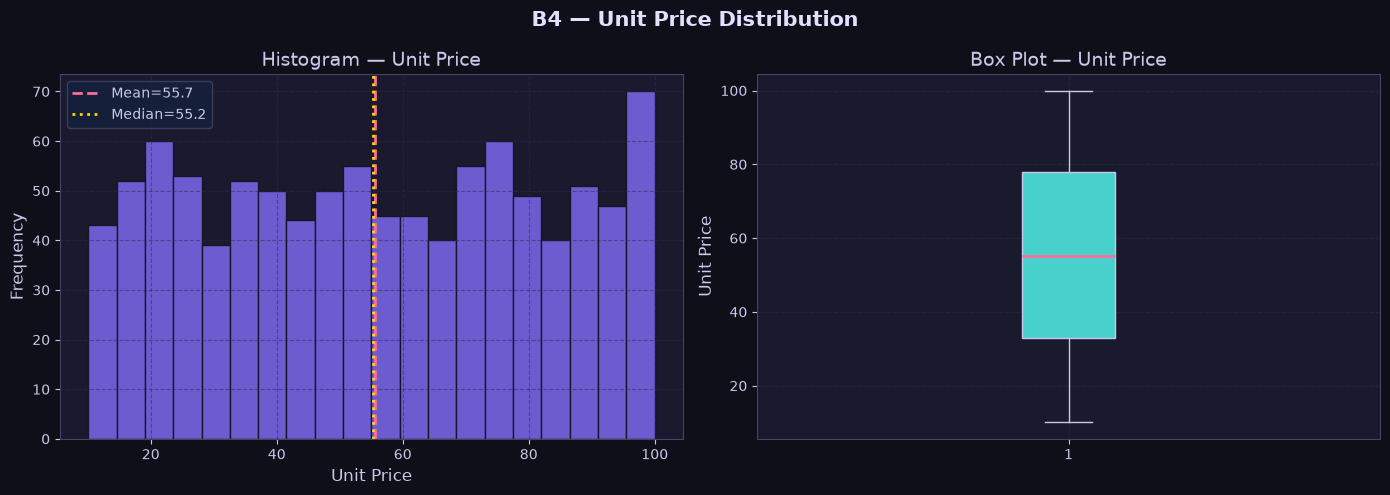

count    1000.00
mean       55.67
std        26.49
min        10.08
25%        32.88
50%        55.23
75%        77.94
max        99.96
Name: Unit price, dtype: float64
Skewness: 0.0071
Interpretation: Unit price 10-100, nearly uniform. Mean~Median, slight positive skew.


In [20]:
# ─── B4.1 Unit Price ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('B4 — Unit Price Distribution', fontsize=15, fontweight='bold', color='#e0e0ff')

axes[0].hist(df_clean['Unit price'], bins=20, color='#7b68ee', edgecolor='#0f0f1a', alpha=0.85)
axes[0].axvline(df_clean['Unit price'].mean(), color='#ff6b9d', lw=2, linestyle='--',
                label=f"Mean={df_clean['Unit price'].mean():.1f}")
axes[0].axvline(df_clean['Unit price'].median(), color='#ffd700', lw=2, linestyle=':',
                label=f"Median={df_clean['Unit price'].median():.1f}")
axes[0].set_title('Histogram — Unit Price')
axes[0].set_xlabel('Unit Price')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True)

axes[1].boxplot(df_clean['Unit price'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='#48d1cc', color='#c8c8e8'),
                medianprops=dict(color='#ff6b9d', lw=2),
                whiskerprops=dict(color='#c8c8e8'),
                capprops=dict(color='#c8c8e8'),
                flierprops=dict(marker='o', color='#ffd700', alpha=0.5))
axes[1].set_title('Box Plot — Unit Price')
axes[1].set_ylabel('Unit Price')
axes[1].grid(True)

plt.tight_layout()
plt.savefig('plot_b4_unitprice.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print(df_clean['Unit price'].describe().round(2))
print(f'Skewness: {df_clean["Unit price"].skew():.4f}')
print('Interpretation: Unit price 10-100, nearly uniform. Mean~Median, slight positive skew.')

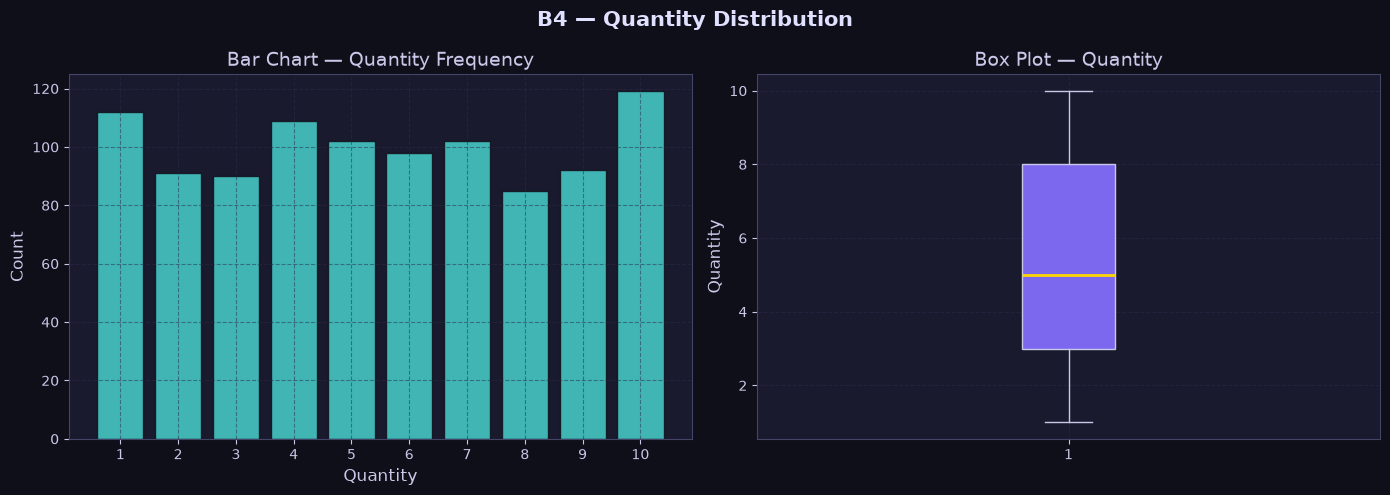

count    1000.00
mean        5.51
std         2.92
min         1.00
25%         3.00
50%         5.00
75%         8.00
max        10.00
Name: Quantity, dtype: float64
Skewness: 0.0129
Interpretation: Quantity 1-10, nearly uniform distribution (near-zero skew).


In [21]:
# ─── B4.2 Quantity ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('B4 — Quantity Distribution', fontsize=15, fontweight='bold', color='#e0e0ff')

qty_counts = df_clean['Quantity'].value_counts().sort_index()
axes[0].bar(qty_counts.index, qty_counts.values, color='#48d1cc', edgecolor='#0f0f1a', alpha=0.85)
axes[0].set_title('Bar Chart — Quantity Frequency')
axes[0].set_xlabel('Quantity')
axes[0].set_ylabel('Count')
axes[0].set_xticks(range(1, 11))
axes[0].grid(True)

axes[1].boxplot(df_clean['Quantity'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='#7b68ee', color='#c8c8e8'),
                medianprops=dict(color='#ffd700', lw=2),
                whiskerprops=dict(color='#c8c8e8'),
                capprops=dict(color='#c8c8e8'))
axes[1].set_title('Box Plot — Quantity')
axes[1].set_ylabel('Quantity')
axes[1].grid(True)

plt.tight_layout()
plt.savefig('plot_b4_quantity.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print(df_clean['Quantity'].describe().round(2))
print(f'Skewness: {df_clean["Quantity"].skew():.4f}')
print('Interpretation: Quantity 1-10, nearly uniform distribution (near-zero skew).')

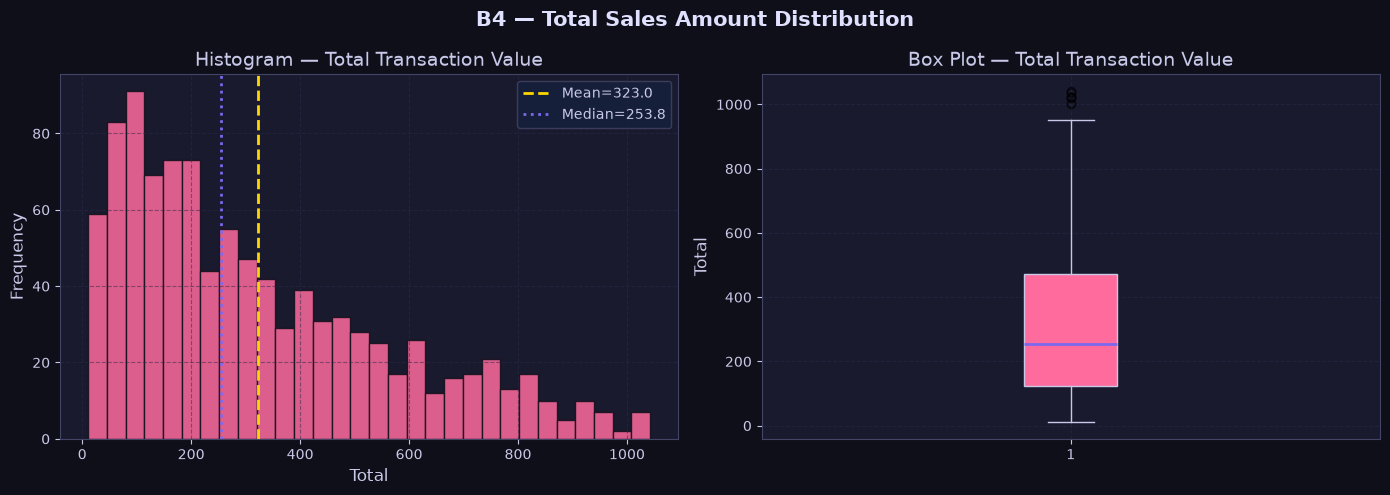

count    1000.00
mean      322.97
std       245.89
min        10.68
25%       124.42
50%       253.85
75%       471.35
max      1042.65
Name: Total, dtype: float64
Skewness: 0.8926
Interpretation: Total is positively skewed; most transactions < 500.


In [22]:
# ─── B4.3 Total Transaction Value ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('B4 — Total Sales Amount Distribution', fontsize=15, fontweight='bold', color='#e0e0ff')

axes[0].hist(df_clean['Total'], bins=30, color='#ff6b9d', edgecolor='#0f0f1a', alpha=0.85)
axes[0].axvline(df_clean['Total'].mean(), color='#ffd700', lw=2, linestyle='--',
                label=f"Mean={df_clean['Total'].mean():.1f}")
axes[0].axvline(df_clean['Total'].median(), color='#7b68ee', lw=2, linestyle=':',
                label=f"Median={df_clean['Total'].median():.1f}")
axes[0].set_title('Histogram — Total Transaction Value')
axes[0].set_xlabel('Total')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True)

axes[1].boxplot(df_clean['Total'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='#ff6b9d', color='#c8c8e8'),
                medianprops=dict(color='#7b68ee', lw=2),
                whiskerprops=dict(color='#c8c8e8'),
                capprops=dict(color='#c8c8e8'),
                flierprops=dict(marker='o', color='#ffd700', alpha=0.5))
axes[1].set_title('Box Plot — Total Transaction Value')
axes[1].set_ylabel('Total')
axes[1].grid(True)

plt.tight_layout()
plt.savefig('plot_b4_total.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print(df_clean['Total'].describe().round(2))
print(f'Skewness: {df_clean["Total"].skew():.4f}')
print('Interpretation: Total is positively skewed; most transactions < 500.')

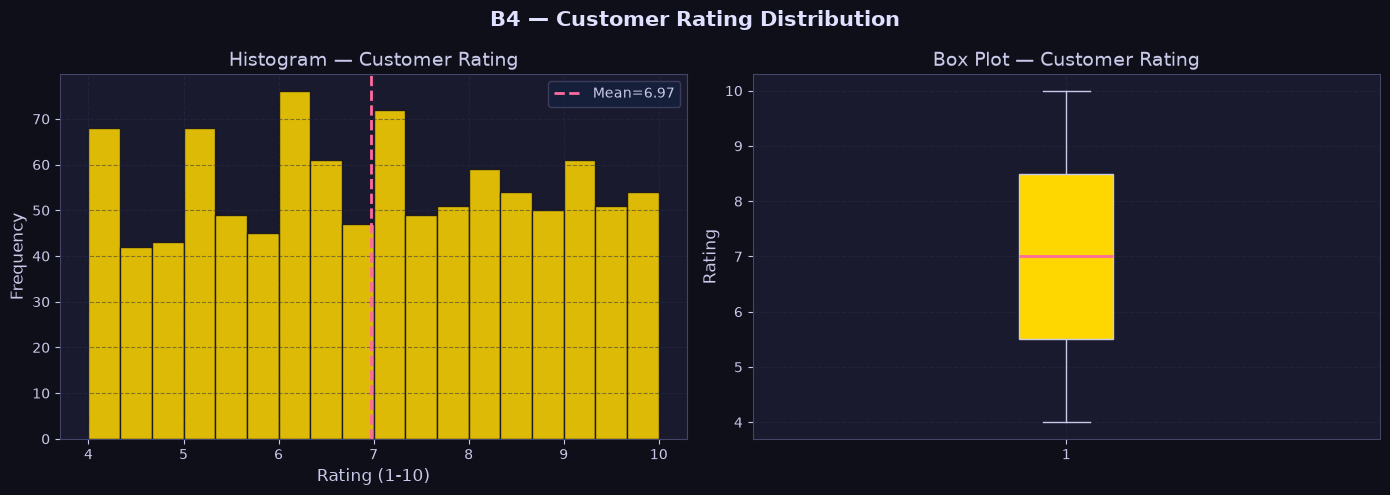

count    1000.000
mean        6.973
std         1.719
min         4.000
25%         5.500
50%         7.000
75%         8.500
max        10.000
Name: Customer stratification rating, dtype: float64
Skewness: 0.0090
Interpretation: Nearly uniform 4-10, mean ~6.97, slight negative skew.


In [23]:
# ─── B4.4 Customer Stratification Rating ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('B4 — Customer Rating Distribution', fontsize=15, fontweight='bold', color='#e0e0ff')

axes[0].hist(df_clean['Customer stratification rating'], bins=18,
             color='#ffd700', edgecolor='#0f0f1a', alpha=0.85)
axes[0].axvline(df_clean['Customer stratification rating'].mean(),
                color='#ff6b9d', lw=2, linestyle='--',
                label=f"Mean={df_clean['Customer stratification rating'].mean():.2f}")
axes[0].set_title('Histogram — Customer Rating')
axes[0].set_xlabel('Rating (1-10)')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True)

axes[1].boxplot(df_clean['Customer stratification rating'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='#ffd700', color='#c8c8e8'),
                medianprops=dict(color='#ff6b9d', lw=2),
                whiskerprops=dict(color='#c8c8e8'),
                capprops=dict(color='#c8c8e8'))
axes[1].set_title('Box Plot — Customer Rating')
axes[1].set_ylabel('Rating')
axes[1].grid(True)

plt.tight_layout()
plt.savefig('plot_b4_rating.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print(df_clean['Customer stratification rating'].describe().round(3))
print(f'Skewness: {df_clean["Customer stratification rating"].skew():.4f}')
print('Interpretation: Nearly uniform 4-10, mean ~6.97, slight negative skew.')

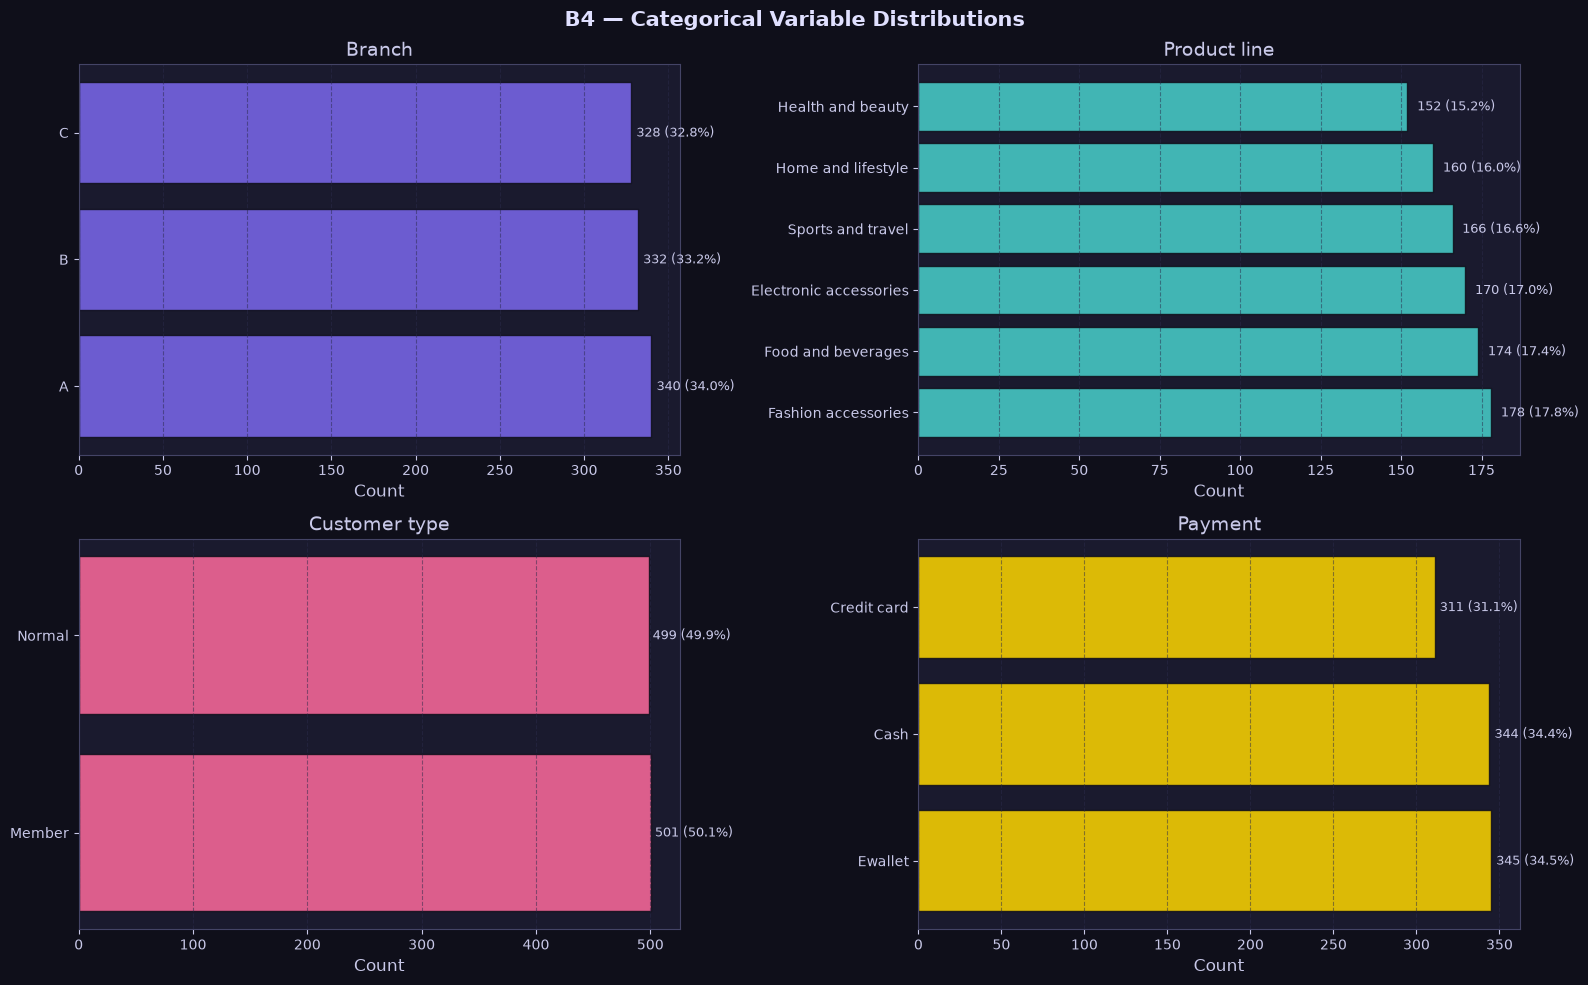

Branch:        ~333 each — balanced across branches
Product line:  143-178 each — balanced
Customer type: ~50/50 Member vs Normal
Payment:       Ewallet 345, Cash 344, Credit card 311 — roughly equal


In [24]:
# ─── B4.5 Categorical Variables ──────────────────────────────────────────────
cat_vars = ['Branch', 'Product line', 'Customer type', 'Payment']
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('B4 — Categorical Variable Distributions', fontsize=15, fontweight='bold', color='#e0e0ff')
axes = axes.flatten()

for i, col in enumerate(cat_vars):
    counts = df_clean[col].value_counts()
    bars = axes[i].barh(counts.index, counts.values, color=PALETTE[i], edgecolor='#0f0f1a', alpha=0.85)
    axes[i].set_title(col)
    axes[i].set_xlabel('Count')
    for bar, val in zip(bars, counts.values):
        axes[i].text(val+3, bar.get_y()+bar.get_height()/2,
                     f'{val} ({val/len(df_clean)*100:.1f}%)', va='center', fontsize=9)
    axes[i].grid(True, axis='x')

plt.tight_layout()
plt.savefig('plot_b4_categorical.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print('Branch:        ~333 each — balanced across branches')
print('Product line:  143-178 each — balanced')
print('Customer type: ~50/50 Member vs Normal')
print('Payment:       Ewallet 345, Cash 344, Credit card 311 — roughly equal')

---
## B5. Bivariate EDA (3 Marks)

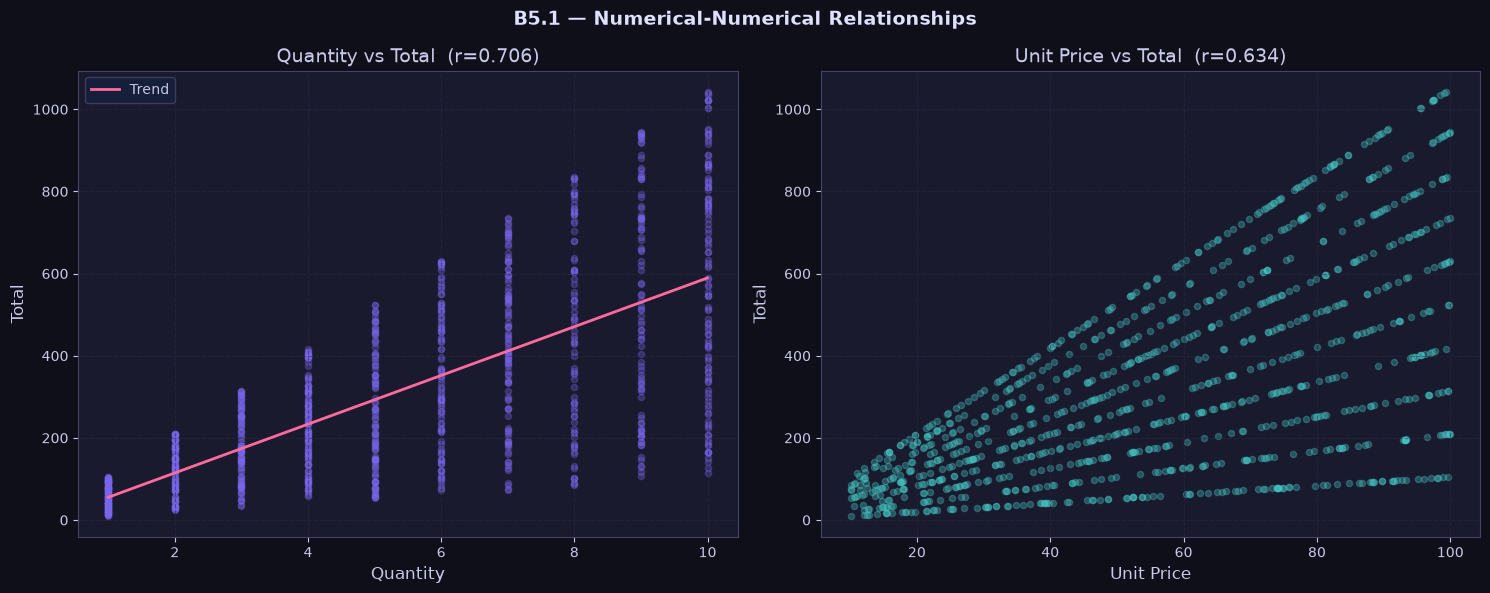

r(Quantity vs Total)  = 0.7055  p=2.0639e-151
r(Unit Price vs Total)= 0.6340  p=1.6100e-113
Interpretation: Both show strong positive r with Total — expected since Total = UnitPrice x Qty x 1.05.
This is a definitional relationship, not a discovered pattern. Rating correlation (B7.5) is more informative.


In [25]:
# ─── B5.1 Numerical-Numerical: Quantity vs Total, Unit Price vs Total ─────────
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('B5.1 — Numerical-Numerical Relationships', fontsize=14, fontweight='bold', color='#e0e0ff')

axes[0].scatter(df_clean['Quantity'], df_clean['Total'], alpha=0.3, color='#7b68ee', s=20)
z = np.polyfit(df_clean['Quantity'], df_clean['Total'], 1)
xr = np.linspace(1, 10, 100)
axes[0].plot(xr, np.poly1d(z)(xr), color='#ff6b9d', lw=2, label='Trend')
r1, p1 = stats.pearsonr(df_clean['Quantity'], df_clean['Total'])
axes[0].set_title(f'Quantity vs Total  (r={r1:.3f})')
axes[0].set_xlabel('Quantity')
axes[0].set_ylabel('Total')
axes[0].legend()
axes[0].grid(True)

axes[1].scatter(df_clean['Unit price'], df_clean['Total'], alpha=0.3, color='#48d1cc', s=20)
r2, p2 = stats.pearsonr(df_clean['Unit price'], df_clean['Total'])
axes[1].set_title(f'Unit Price vs Total  (r={r2:.3f})')
axes[1].set_xlabel('Unit Price')
axes[1].set_ylabel('Total')
axes[1].grid(True)

plt.tight_layout()
plt.savefig('plot_b5_numnum.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print(f'r(Quantity vs Total)  = {r1:.4f}  p={p1:.4e}')
print(f'r(Unit Price vs Total)= {r2:.4f}  p={p2:.4e}')
print('Interpretation: Both show strong positive r with Total — expected since Total = UnitPrice x Qty x 1.05.')
print('This is a definitional relationship, not a discovered pattern. Rating correlation (B7.5) is more informative.')

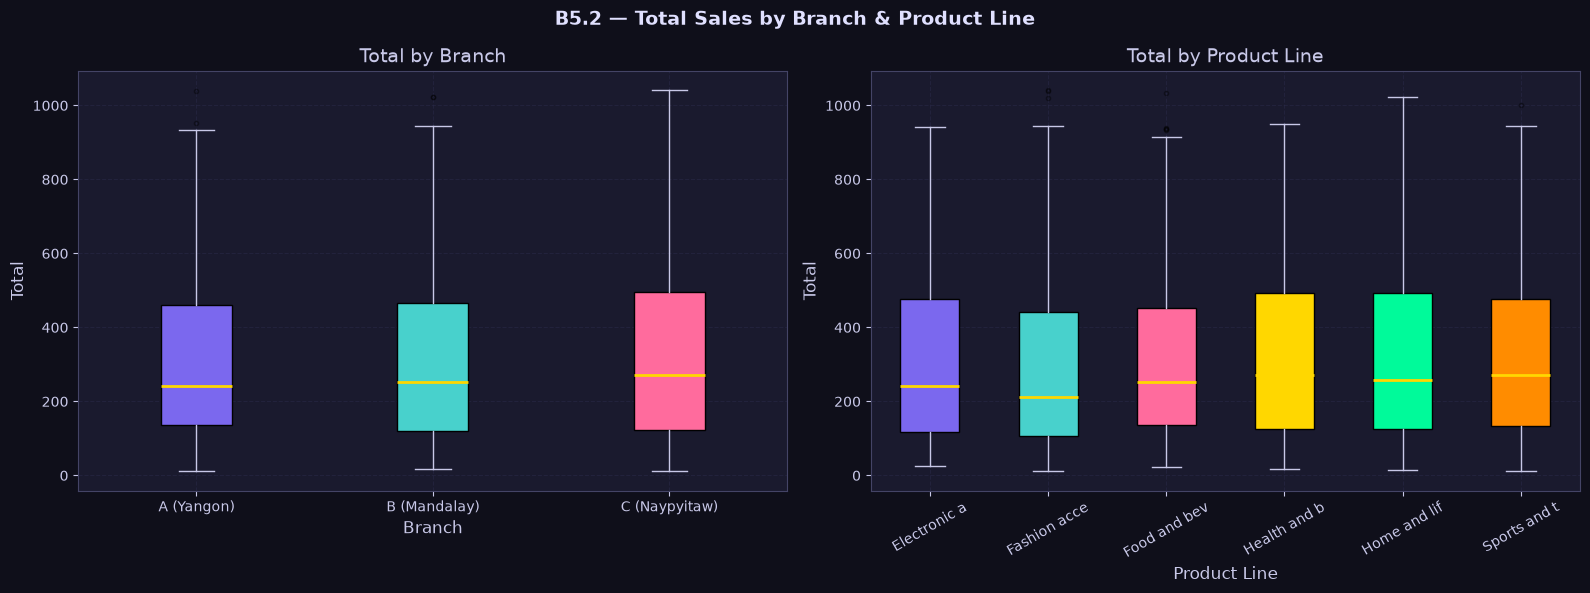

Mean Total by Branch:
Branch
A    312.35
B    319.87
C    337.10
Name: Total, dtype: float64

Mean Total by Product Line:
Product line
Home and lifestyle        336.64
Sports and travel         332.07
Health and beauty         323.64
Food and beverages        322.67
Electronic accessories    319.63
Fashion accessories       305.09
Name: Total, dtype: float64

Interpretation: Branch means within 2% of each other — distributions heavily overlap.
Product line variation also modest; Home & Lifestyle slightly higher average transaction.


In [26]:
# ─── B5.2 Numerical-Categorical: Total by Branch & Product Line ───────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('B5.2 — Total Sales by Branch & Product Line', fontsize=14, fontweight='bold', color='#e0e0ff')

branch_groups = [df_clean[df_clean['Branch']==b]['Total'] for b in ['A','B','C']]
bp1 = axes[0].boxplot(branch_groups, tick_labels=['A (Yangon)','B (Mandalay)','C (Naypyitaw)'],
                       patch_artist=True,
                       medianprops=dict(color='#ffd700', lw=2),
                       whiskerprops=dict(color='#c8c8e8'),
                       capprops=dict(color='#c8c8e8'),
                       flierprops=dict(marker='o', color='#ff6b9d', alpha=0.4, ms=3))
for j, box in enumerate(bp1['boxes']):
    box.set_facecolor(PALETTE[j])
axes[0].set_title('Total by Branch')
axes[0].set_xlabel('Branch')
axes[0].set_ylabel('Total')
axes[0].grid(True)

prod_lines = sorted(df_clean['Product line'].unique())
prod_groups = [df_clean[df_clean['Product line']==p]['Total'] for p in prod_lines]
bp2 = axes[1].boxplot(prod_groups, tick_labels=[pl[:12] for pl in prod_lines],
                       patch_artist=True,
                       medianprops=dict(color='#ffd700', lw=2),
                       whiskerprops=dict(color='#c8c8e8'),
                       capprops=dict(color='#c8c8e8'),
                       flierprops=dict(marker='o', color='#ff6b9d', alpha=0.4, ms=3))
for j, box in enumerate(bp2['boxes']):
    box.set_facecolor(PALETTE[j % len(PALETTE)])
axes[1].set_title('Total by Product Line')
axes[1].set_xlabel('Product Line')
axes[1].set_ylabel('Total')
axes[1].tick_params(axis='x', labelrotation=30)
axes[1].grid(True)

plt.tight_layout()
plt.savefig('plot_b5_numcat.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print('Mean Total by Branch:')
print(df_clean.groupby('Branch')['Total'].mean().round(2))
print('\nMean Total by Product Line:')
print(df_clean.groupby('Product line')['Total'].mean().round(2).sort_values(ascending=False))
print('\nInterpretation: Branch means within 2% of each other — distributions heavily overlap.')
print('Product line variation also modest; Home & Lifestyle slightly higher average transaction.')

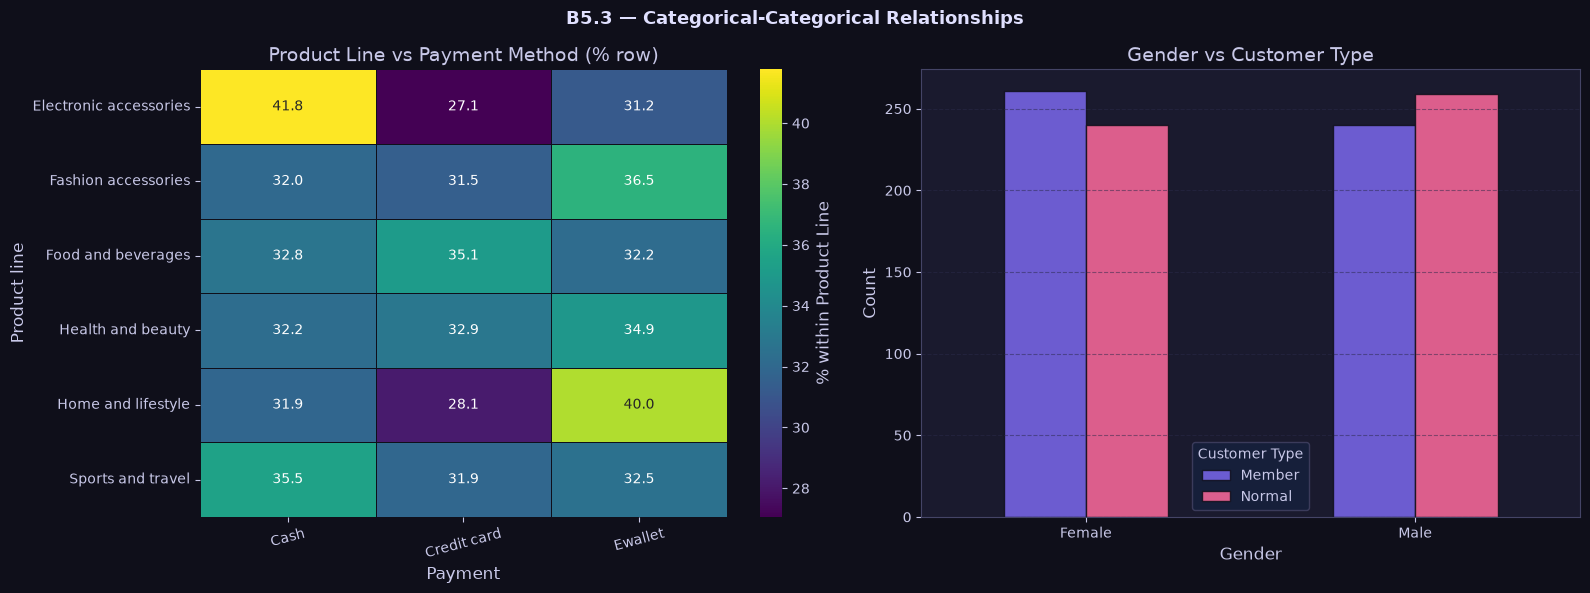

Chi-square (Product line vs Payment): chi2=8.721, p=0.5587, dof=10
=> No significant association
Chi-square (Gender vs Customer type): chi2=1.444, p=0.2295
=> No significant association between gender and membership


In [27]:
# ─── B5.3 Categorical-Categorical: Product Line vs Payment, Gender vs Cust Type -
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('B5.3 — Categorical-Categorical Relationships', fontsize=13, fontweight='bold', color='#e0e0ff')

ct1 = pd.crosstab(df_clean['Product line'], df_clean['Payment'], normalize='index') * 100
sns.heatmap(ct1, ax=axes[0], annot=True, fmt='.1f', cmap='viridis',
            linecolor='#0f0f1a', linewidths=0.5, cbar_kws={'label': '% within Product Line'})
axes[0].set_title('Product Line vs Payment Method (% row)')
axes[0].tick_params(axis='x', labelrotation=15)

ct2 = pd.crosstab(df_clean['Gender'], df_clean['Customer type'])
ct2.plot(kind='bar', ax=axes[1], color=[PALETTE[0], PALETTE[2]], edgecolor='#0f0f1a', alpha=0.85)
axes[1].set_title('Gender vs Customer Type')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', labelrotation=0)
axes[1].legend(title='Customer Type')
axes[1].grid(True, axis='y')

plt.tight_layout()
plt.savefig('plot_b5_catcat.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

ct_raw = pd.crosstab(df_clean['Product line'], df_clean['Payment'])
chi2, p, dof, _ = stats.chi2_contingency(ct_raw)
print(f'Chi-square (Product line vs Payment): chi2={chi2:.3f}, p={p:.4f}, dof={dof}')
print(f'=> {"Significant association" if p<0.05 else "No significant association"}')

ct2b = pd.crosstab(df_clean['Gender'], df_clean['Customer type'])
chi2b, pb, _, _ = stats.chi2_contingency(ct2b)
print(f'Chi-square (Gender vs Customer type): chi2={chi2b:.3f}, p={pb:.4f}')
print(f'=> {"Significant association" if pb<0.05 else "No significant association between gender and membership"}')

---
## B6. Multivariate EDA (3 Marks)

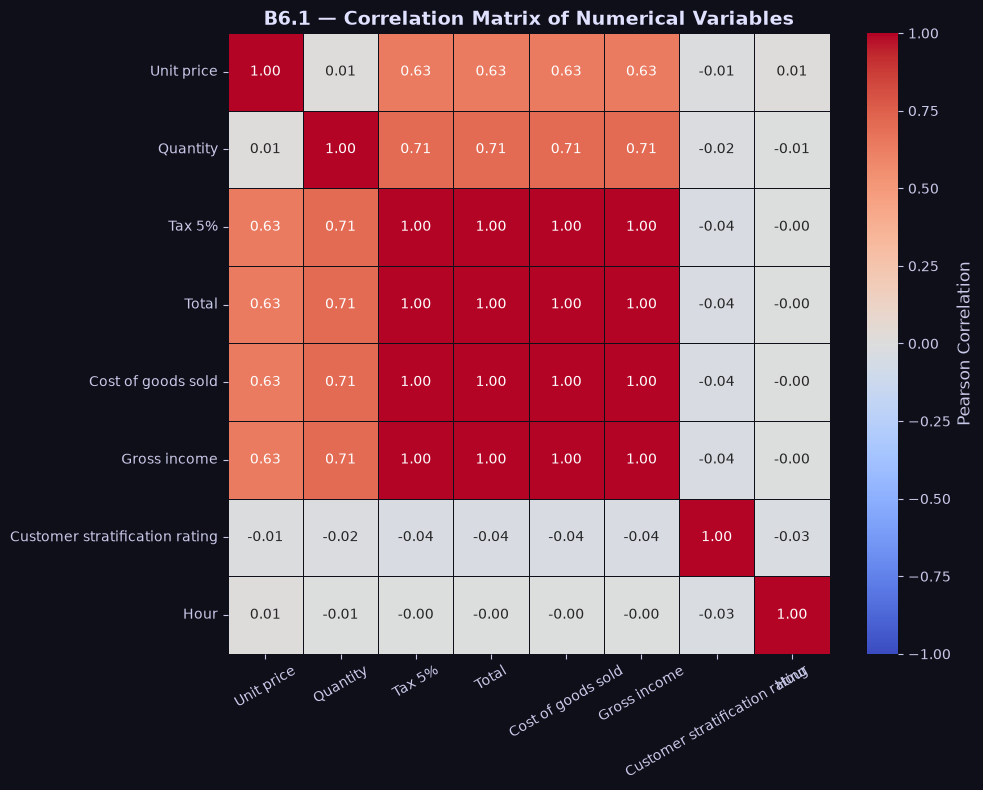

Key findings:
* Tax 5%, COGS, Gross income, Total are perfectly correlated (r=1.0) -- all derived from UnitPrice x Qty.
* Customer rating has near-zero correlation with all financial variables.
* Hour also near-zero with financial variables -- time of day does not drive transaction size.


In [28]:
# ─── B6.1 Correlation Matrix ─────────────────────────────────────────────────
num_features = ['Unit price', 'Quantity', 'Tax 5%', 'Total',
                'Cost of goods sold', 'Gross income',
                'Customer stratification rating', 'Hour']
corr_matrix = df_clean[num_features].corr().round(3)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, ax=ax, annot=True, fmt='.2f', cmap='coolwarm',
            linecolor='#0f0f1a', linewidths=0.5, center=0, vmin=-1, vmax=1,
            cbar_kws={'label': 'Pearson Correlation'})
ax.set_title('B6.1 — Correlation Matrix of Numerical Variables',
             fontsize=14, fontweight='bold', color='#e0e0ff')
ax.tick_params(axis='x', labelrotation=30)
ax.tick_params(axis='y', labelrotation=0)
plt.tight_layout()
plt.savefig('plot_b6_corrmatrix.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print('Key findings:')
print('* Tax 5%, COGS, Gross income, Total are perfectly correlated (r=1.0) -- all derived from UnitPrice x Qty.')
print('* Customer rating has near-zero correlation with all financial variables.')
print('* Hour also near-zero with financial variables -- time of day does not drive transaction size.')

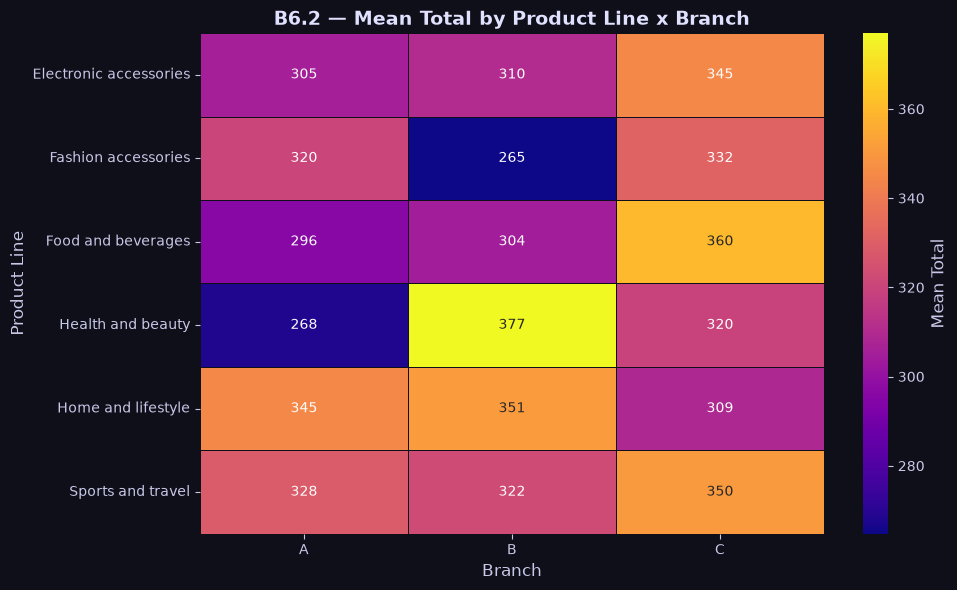

Branch                       A       B       C
Product line                                  
Electronic accessories  305.29  310.03  344.89
Fashion accessories     320.25  264.73  331.69
Food and beverages      295.92  304.30  360.10
Health and beauty       268.04  376.99  319.53
Home and lifestyle      344.88  350.98  308.79
Sports and travel       328.35  322.39  350.27

Interpretation:
Adding Branch as a 3rd variable reveals within-category branch variation.
Health & Beauty at Branch C (Naypyitaw) shows slightly higher mean total.
No single product line dominates across all branches.


In [29]:
# ─── B6.2 Mean Total: Branch x Product Line ──────────────────────────────────
pivot = df_clean.pivot_table(values='Total', index='Product line',
                              columns='Branch', aggfunc='mean').round(2)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot, ax=ax, annot=True, fmt='.0f', cmap='plasma',
            linecolor='#0f0f1a', linewidths=0.5,
            cbar_kws={'label': 'Mean Total'})
ax.set_title('B6.2 — Mean Total by Product Line x Branch',
             fontsize=14, fontweight='bold', color='#e0e0ff')
ax.set_xlabel('Branch')
ax.set_ylabel('Product Line')
plt.tight_layout()
plt.savefig('plot_b6_branch_product.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print(pivot)
print('\nInterpretation:')
print('Adding Branch as a 3rd variable reveals within-category branch variation.')
print('Health & Beauty at Branch C (Naypyitaw) shows slightly higher mean total.')
print('No single product line dominates across all branches.')

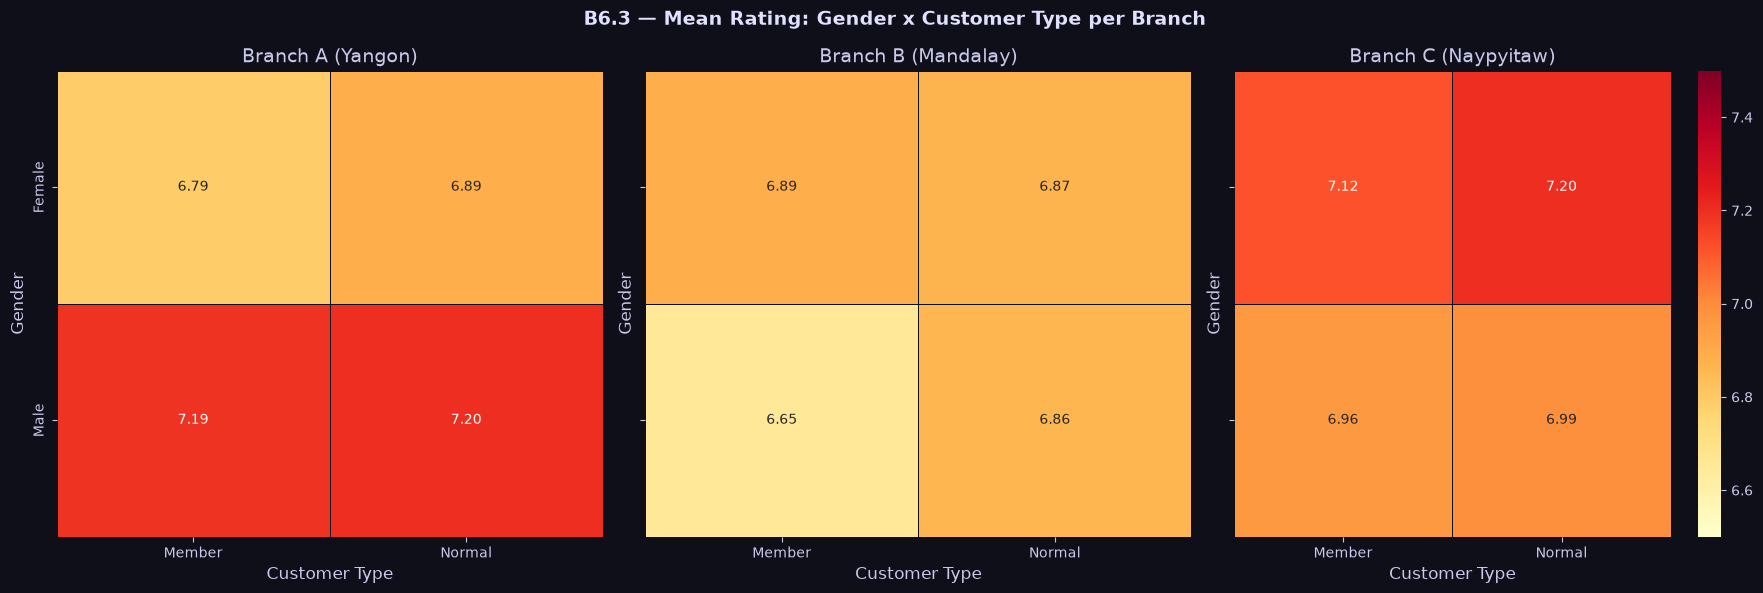

Rating differences across Gender x Customer type x Branch are all within ~0.3 points.
No meaningful 3-way interaction -- rating is largely independent of these factors.


In [30]:
# ─── B6.3 Rating by Gender x Customer Type (per Branch) ─────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
fig.suptitle('B6.3 — Mean Rating: Gender x Customer Type per Branch',
             fontsize=14, fontweight='bold', color='#e0e0ff')

city_map = {'A': 'Yangon', 'B': 'Mandalay', 'C': 'Naypyitaw'}
for i, branch in enumerate(['A', 'B', 'C']):
    sub = df_clean[df_clean['Branch'] == branch]
    piv = sub.pivot_table(values='Customer stratification rating',
                          index='Gender', columns='Customer type', aggfunc='mean').round(2)
    sns.heatmap(piv, ax=axes[i], annot=True, fmt='.2f',
                cmap='YlOrRd', vmin=6.5, vmax=7.5,
                linecolor='#0f0f1a', linewidths=0.5, cbar=(i == 2))
    axes[i].set_title(f'Branch {branch} ({city_map[branch]})')
    axes[i].set_xlabel('Customer Type')
    if i == 0:
        axes[i].set_ylabel('Gender')

plt.tight_layout()
plt.savefig('plot_b6_rating_multivar.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print('Rating differences across Gender x Customer type x Branch are all within ~0.3 points.')
print('No meaningful 3-way interaction -- rating is largely independent of these factors.')

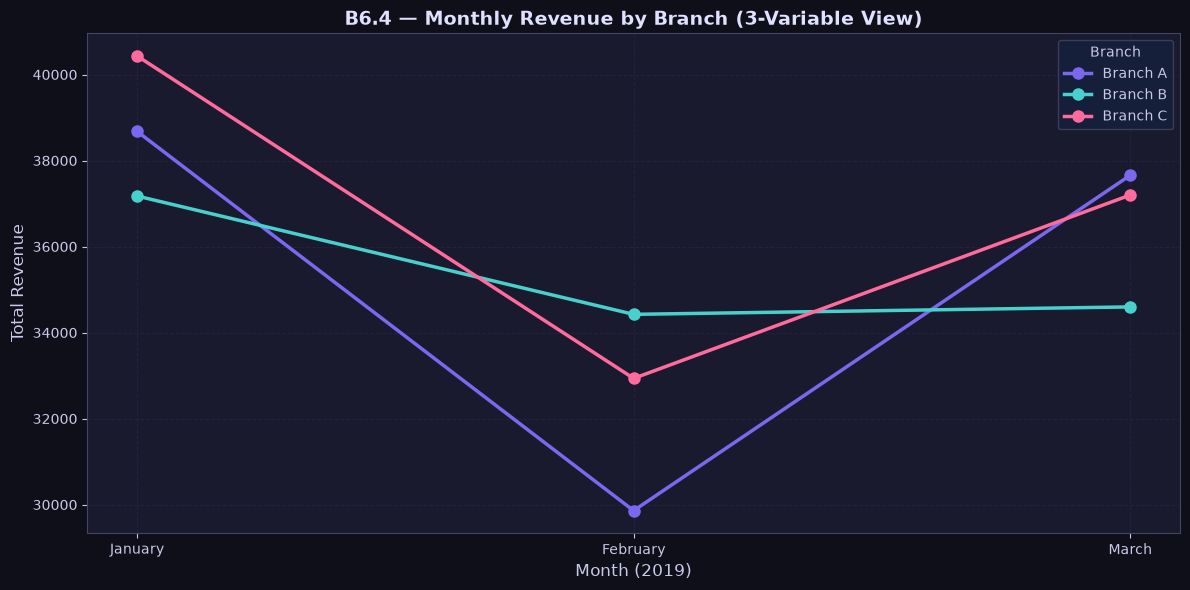

Branch           A        B        C
Month_num                           
1          38681.0  37176.0  40435.0
2          29860.0  34424.0  32935.0
3          37659.0  34597.0  37199.0

Interpretation: January is strongest for Branch A and C; Branch B peaks in February.
A 3-variable pattern invisible in bivariate analysis of Month or Branch alone.


In [31]:
# ─── B6.4 Monthly Revenue by Branch ──────────────────────────────────────────
monthly_branch = df_clean.groupby(['Month_num', 'Branch'])['Total'].sum().reset_index()
month_labels = {1: 'January', 2: 'February', 3: 'March'}

fig, ax = plt.subplots(figsize=(12, 6))
for i, branch in enumerate(['A', 'B', 'C']):
    sub = monthly_branch[monthly_branch['Branch'] == branch]
    ax.plot(sub['Month_num'], sub['Total'], marker='o', lw=2.5,
            color=PALETTE[i], label=f'Branch {branch}', ms=8)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['January', 'February', 'March'])
ax.set_title('B6.4 — Monthly Revenue by Branch (3-Variable View)',
             fontsize=14, fontweight='bold', color='#e0e0ff')
ax.set_xlabel('Month (2019)')
ax.set_ylabel('Total Revenue')
ax.legend(title='Branch')
ax.grid(True)
plt.tight_layout()
plt.savefig('plot_b6_monthly_branch.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print(df_clean.groupby(['Month_num', 'Branch'])['Total'].sum().unstack().round(0))
print('\nInterpretation: January is strongest for Branch A and C; Branch B peaks in February.')
print('A 3-variable pattern invisible in bivariate analysis of Month or Branch alone.')

---
## B7. Supermarket Sales-Specific Analytical Questions (2 Marks)

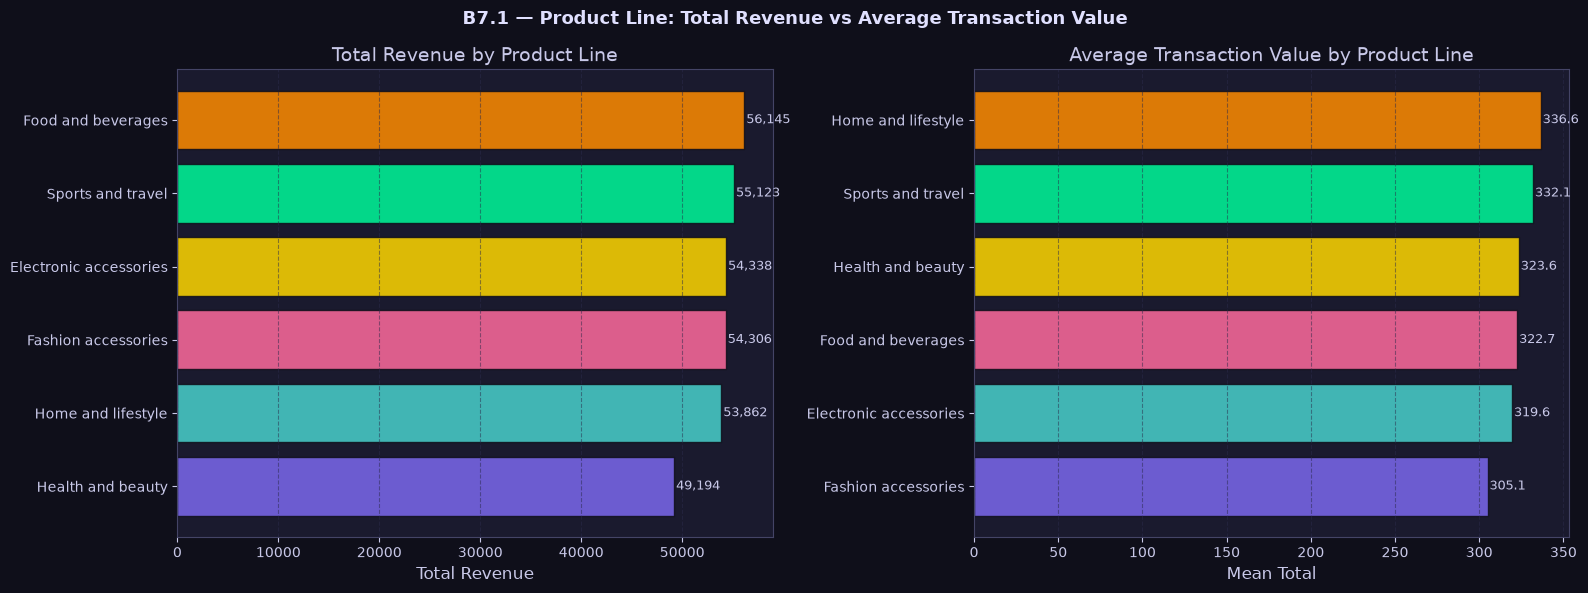

Total Revenue by Product Line:
Product line
Food and beverages        56145.0
Sports and travel         55123.0
Electronic accessories    54338.0
Fashion accessories       54306.0
Home and lifestyle        53862.0
Health and beauty         49194.0
Name: Total, dtype: float64

Average Transaction Value:
Product line
Home and lifestyle        336.64
Sports and travel         332.07
Health and beauty         323.64
Food and beverages        322.67
Electronic accessories    319.63
Fashion accessories       305.09
Name: Total, dtype: float64

Interpretation: Food & Beverages leads by total; Home & Lifestyle has highest avg value.
Ranking changes when normalised -- strategy differs for high-volume vs high-value categories.


In [32]:
# ─── B7.1 Product Line Revenue vs Avg Transaction Value ─────────────────────
prod_total = df_clean.groupby('Product line')['Total'].sum().sort_values(ascending=False)
prod_avg   = df_clean.groupby('Product line')['Total'].mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('B7.1 — Product Line: Total Revenue vs Average Transaction Value',
             fontsize=13, fontweight='bold', color='#e0e0ff')

bars1 = axes[0].barh(prod_total.index[::-1], prod_total.values[::-1],
                      color=PALETTE[:6], edgecolor='#0f0f1a', alpha=0.85)
axes[0].set_title('Total Revenue by Product Line')
axes[0].set_xlabel('Total Revenue')
for bar, val in zip(bars1, prod_total.values[::-1]):
    axes[0].text(val+200, bar.get_y()+bar.get_height()/2, f'{val:,.0f}', va='center', fontsize=9)
axes[0].grid(True, axis='x')

bars2 = axes[1].barh(prod_avg.index[::-1], prod_avg.values[::-1],
                      color=PALETTE[:6], edgecolor='#0f0f1a', alpha=0.85)
axes[1].set_title('Average Transaction Value by Product Line')
axes[1].set_xlabel('Mean Total')
for bar, val in zip(bars2, prod_avg.values[::-1]):
    axes[1].text(val+1, bar.get_y()+bar.get_height()/2, f'{val:.1f}', va='center', fontsize=9)
axes[1].grid(True, axis='x')

plt.tight_layout()
plt.savefig('plot_b7_q1.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print('Total Revenue by Product Line:')
print(prod_total.round(0))
print('\nAverage Transaction Value:')
print(prod_avg.round(2))
print('\nInterpretation: Food & Beverages leads by total; Home & Lifestyle has highest avg value.')
print('Ranking changes when normalised -- strategy differs for high-volume vs high-value categories.')

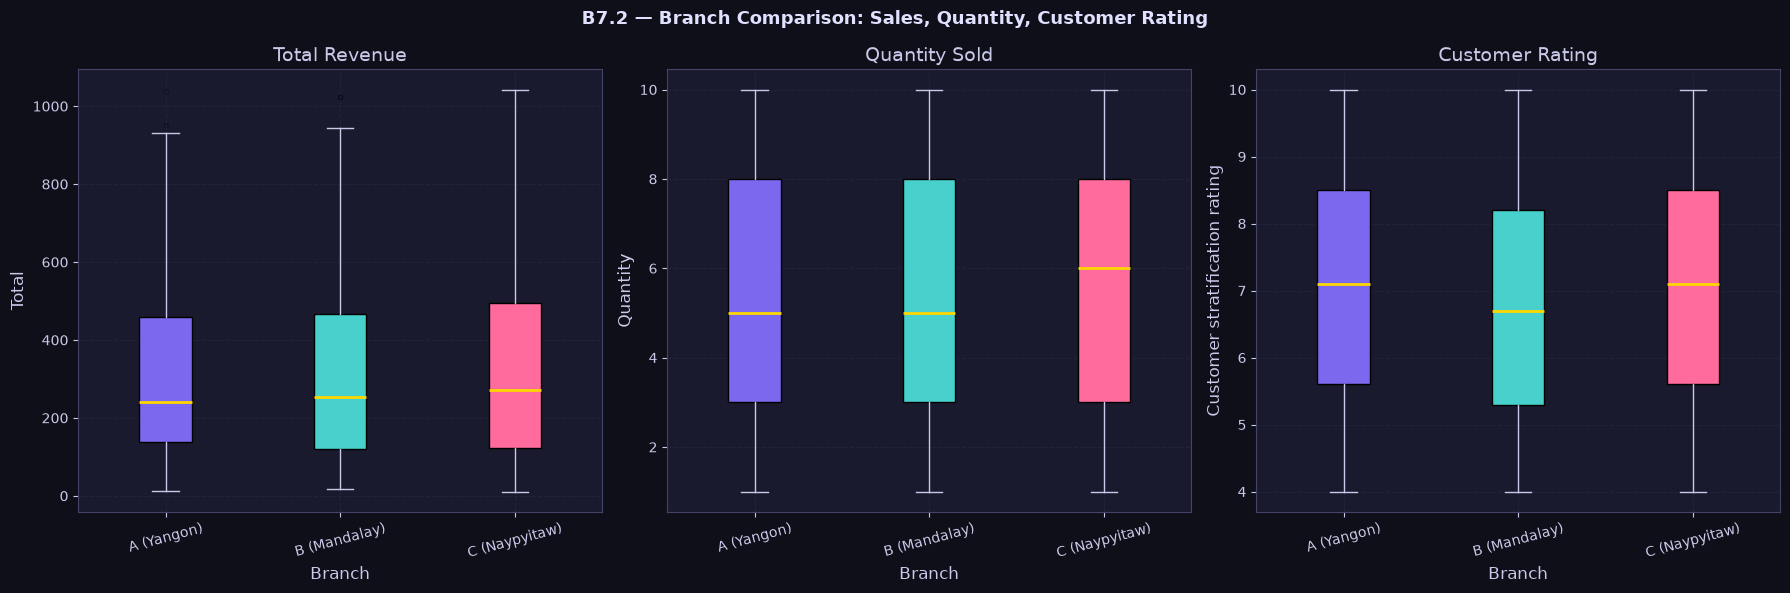

ANOVA (Total by Branch): F=0.885, p=0.4132
=> No significant difference across branches.

Branch means:
         Total  Quantity  Customer stratification rating
Branch                                                  
A       312.35      5.47                            7.03
B       319.87      5.48                            6.82
C       337.10      5.58                            7.07


In [33]:
# ─── B7.2 Branch/City Differences ────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('B7.2 — Branch Comparison: Sales, Quantity, Customer Rating',
             fontsize=13, fontweight='bold', color='#e0e0ff')

metrics = ['Total', 'Quantity', 'Customer stratification rating']
titles  = ['Total Revenue', 'Quantity Sold', 'Customer Rating']

for i, (metric, title) in enumerate(zip(metrics, titles)):
    grps = [df_clean[df_clean['Branch']==b][metric] for b in ['A','B','C']]
    bp = axes[i].boxplot(grps, tick_labels=['A (Yangon)','B (Mandalay)','C (Naypyitaw)'],
                          patch_artist=True,
                          medianprops=dict(color='#ffd700', lw=2),
                          whiskerprops=dict(color='#c8c8e8'),
                          capprops=dict(color='#c8c8e8'),
                          flierprops=dict(marker='o', alpha=0.3, ms=3))
    for j, box in enumerate(bp['boxes']):
        box.set_facecolor(PALETTE[j])
    axes[i].set_title(title)
    axes[i].set_xlabel('Branch')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', labelrotation=15)
    axes[i].grid(True)

plt.tight_layout()
plt.savefig('plot_b7_q2.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

f_stat, p_anova = stats.f_oneway(*[df_clean[df_clean['Branch']==b]['Total'] for b in ['A','B','C']])
print(f'ANOVA (Total by Branch): F={f_stat:.3f}, p={p_anova:.4f}')
print(f'=>{" Significant" if p_anova<0.05 else " No significant"} difference across branches.')
print('\nBranch means:')
print(df_clean.groupby('Branch')[['Total','Quantity','Customer stratification rating']].mean().round(2))

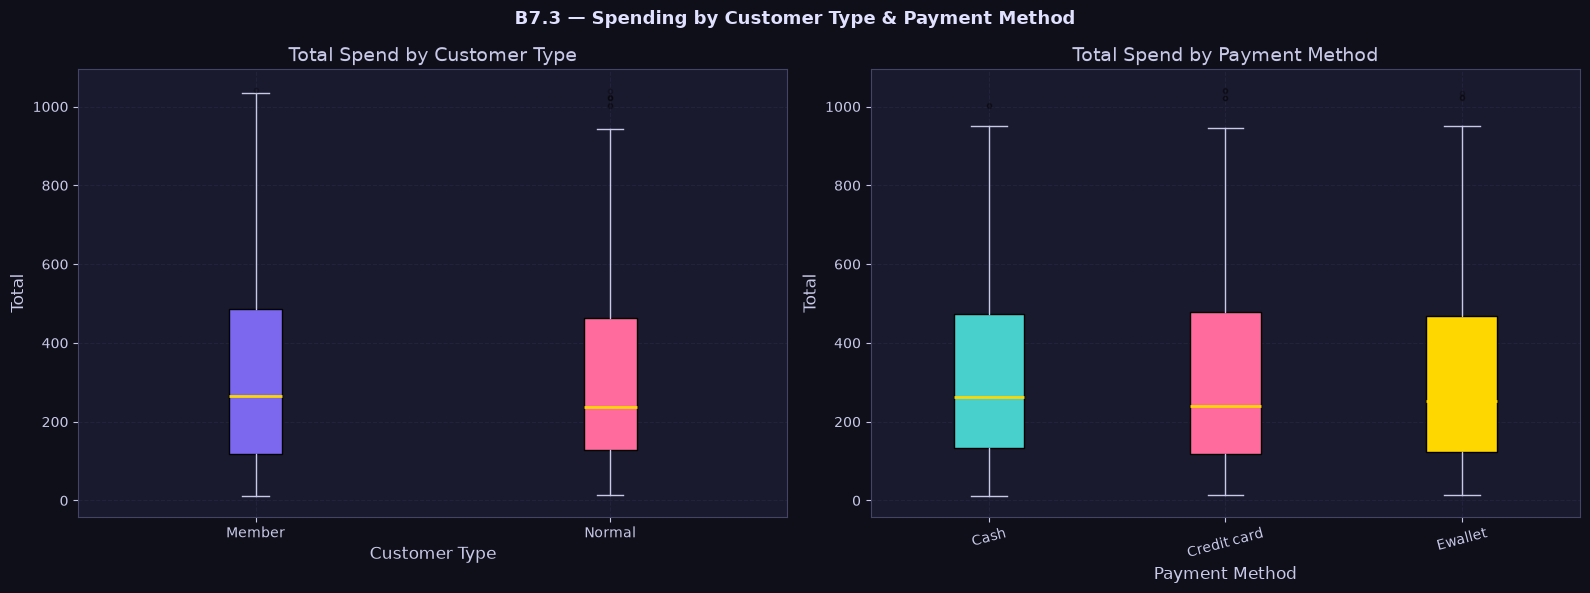

T-test (Member vs Normal): t=0.622, p=0.5344
=> No significant difference in spending.

Mean Total by Payment:
Payment
Cash           326.18
Credit card    324.01
Ewallet        318.82
Name: Total, dtype: float64


In [34]:
# ─── B7.3 Member vs Normal & Payment Method ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('B7.3 — Spending by Customer Type & Payment Method',
             fontsize=13, fontweight='bold', color='#e0e0ff')

cust_grps = [df_clean[df_clean['Customer type']==t]['Total'] for t in ['Member','Normal']]
bp1 = axes[0].boxplot(cust_grps, tick_labels=['Member','Normal'], patch_artist=True,
                       medianprops=dict(color='#ffd700', lw=2),
                       whiskerprops=dict(color='#c8c8e8'),
                       capprops=dict(color='#c8c8e8'),
                       flierprops=dict(marker='o', alpha=0.3, ms=3))
bp1['boxes'][0].set_facecolor(PALETTE[0])
bp1['boxes'][1].set_facecolor(PALETTE[2])
axes[0].set_title('Total Spend by Customer Type')
axes[0].set_xlabel('Customer Type')
axes[0].set_ylabel('Total')
axes[0].grid(True)

pay_methods = sorted(df_clean['Payment'].unique())
pay_grps = [df_clean[df_clean['Payment']==p]['Total'] for p in pay_methods]
bp2 = axes[1].boxplot(pay_grps, tick_labels=pay_methods, patch_artist=True,
                       medianprops=dict(color='#ffd700', lw=2),
                       whiskerprops=dict(color='#c8c8e8'),
                       capprops=dict(color='#c8c8e8'),
                       flierprops=dict(marker='o', alpha=0.3, ms=3))
for j, box in enumerate(bp2['boxes']):
    box.set_facecolor(PALETTE[j+1])
axes[1].set_title('Total Spend by Payment Method')
axes[1].set_xlabel('Payment Method')
axes[1].set_ylabel('Total')
axes[1].tick_params(axis='x', labelrotation=15)
axes[1].grid(True)

plt.tight_layout()
plt.savefig('plot_b7_q3.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

t, p = stats.ttest_ind(
    df_clean[df_clean['Customer type']=='Member']['Total'],
    df_clean[df_clean['Customer type']=='Normal']['Total']
)
print(f'T-test (Member vs Normal): t={t:.3f}, p={p:.4f}')
print(f'=>{" Significant" if p<0.05 else " No significant"} difference in spending.')
print('\nMean Total by Payment:')
print(df_clean.groupby('Payment')['Total'].mean().round(2))

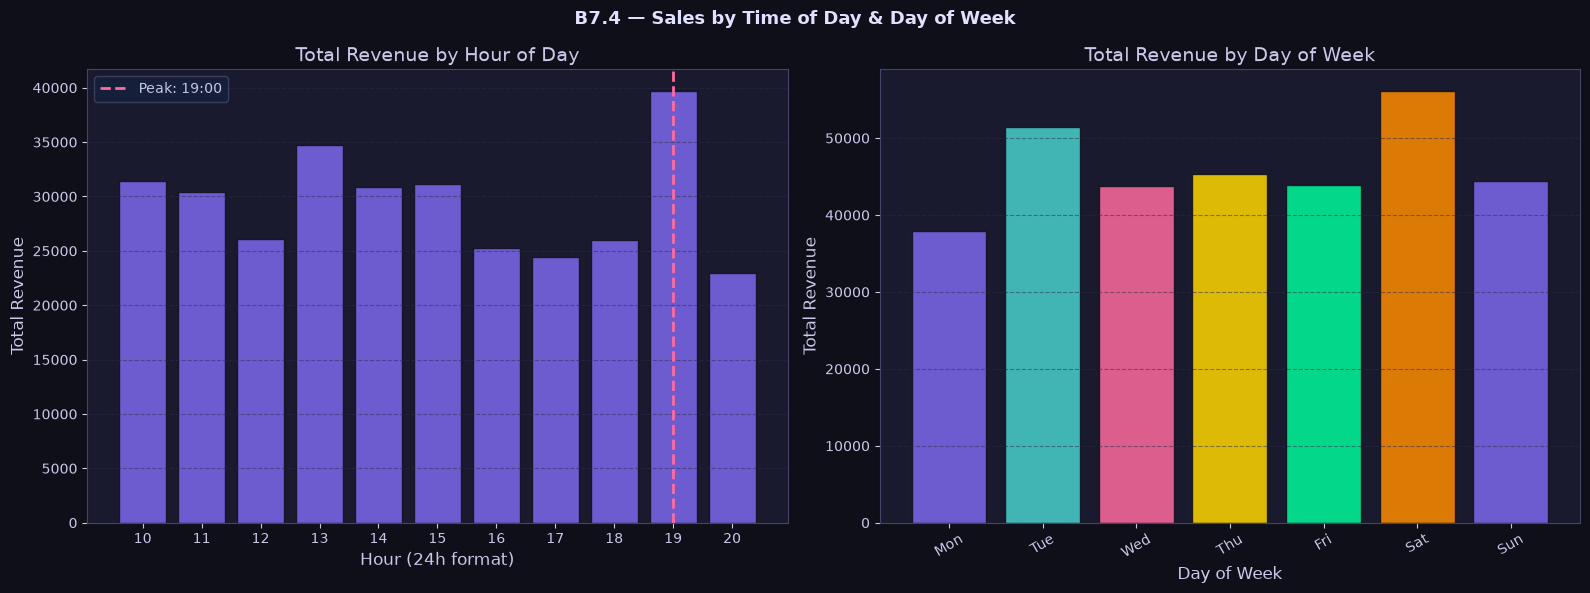

Peak revenue hour: 19:00

Revenue by day (top 3):
Weekday
Saturday    56121.0
Tuesday     51482.0
Thursday    45349.0
Name: Total, dtype: float64

Interpretation: Evening hours 19:00 peak. Saturday and Tuesday tend busiest.
Morning (10-12) is quietest -- consistent with after-work shopping behaviour.


In [35]:
# ─── B7.4 Sales by Time of Day & Day of Week ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('B7.4 — Sales by Time of Day & Day of Week',
             fontsize=13, fontweight='bold', color='#e0e0ff')

hourly = df_clean.groupby('Hour')['Total'].sum().reset_index()
axes[0].bar(hourly['Hour'], hourly['Total'], color='#7b68ee', edgecolor='#0f0f1a', alpha=0.85)
peak_hour = hourly.loc[hourly['Total'].idxmax(), 'Hour']
axes[0].axvline(peak_hour, color='#ff6b9d', lw=2, linestyle='--', label=f'Peak: {peak_hour}:00')
axes[0].set_title('Total Revenue by Hour of Day')
axes[0].set_xlabel('Hour (24h format)')
axes[0].set_ylabel('Total Revenue')
axes[0].set_xticks(hourly['Hour'])
axes[0].legend()
axes[0].grid(True, axis='y')

day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday = df_clean.groupby('Weekday')['Total'].sum().reindex(day_order)
axes[1].bar(range(7), weekday.values, color=PALETTE[:7], edgecolor='#0f0f1a', alpha=0.85)
axes[1].set_xticks(range(7))
axes[1].set_xticklabels([d[:3] for d in day_order], rotation=30)
axes[1].set_title('Total Revenue by Day of Week')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Total Revenue')
axes[1].grid(True, axis='y')

plt.tight_layout()
plt.savefig('plot_b7_q4.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print(f'Peak revenue hour: {peak_hour}:00')
print('\nRevenue by day (top 3):')
print(weekday.sort_values(ascending=False).head(3).round(0))
print('\nInterpretation: Evening hours 19:00 peak. Saturday and Tuesday tend busiest.')
print('Morning (10-12) is quietest -- consistent with after-work shopping behaviour.')

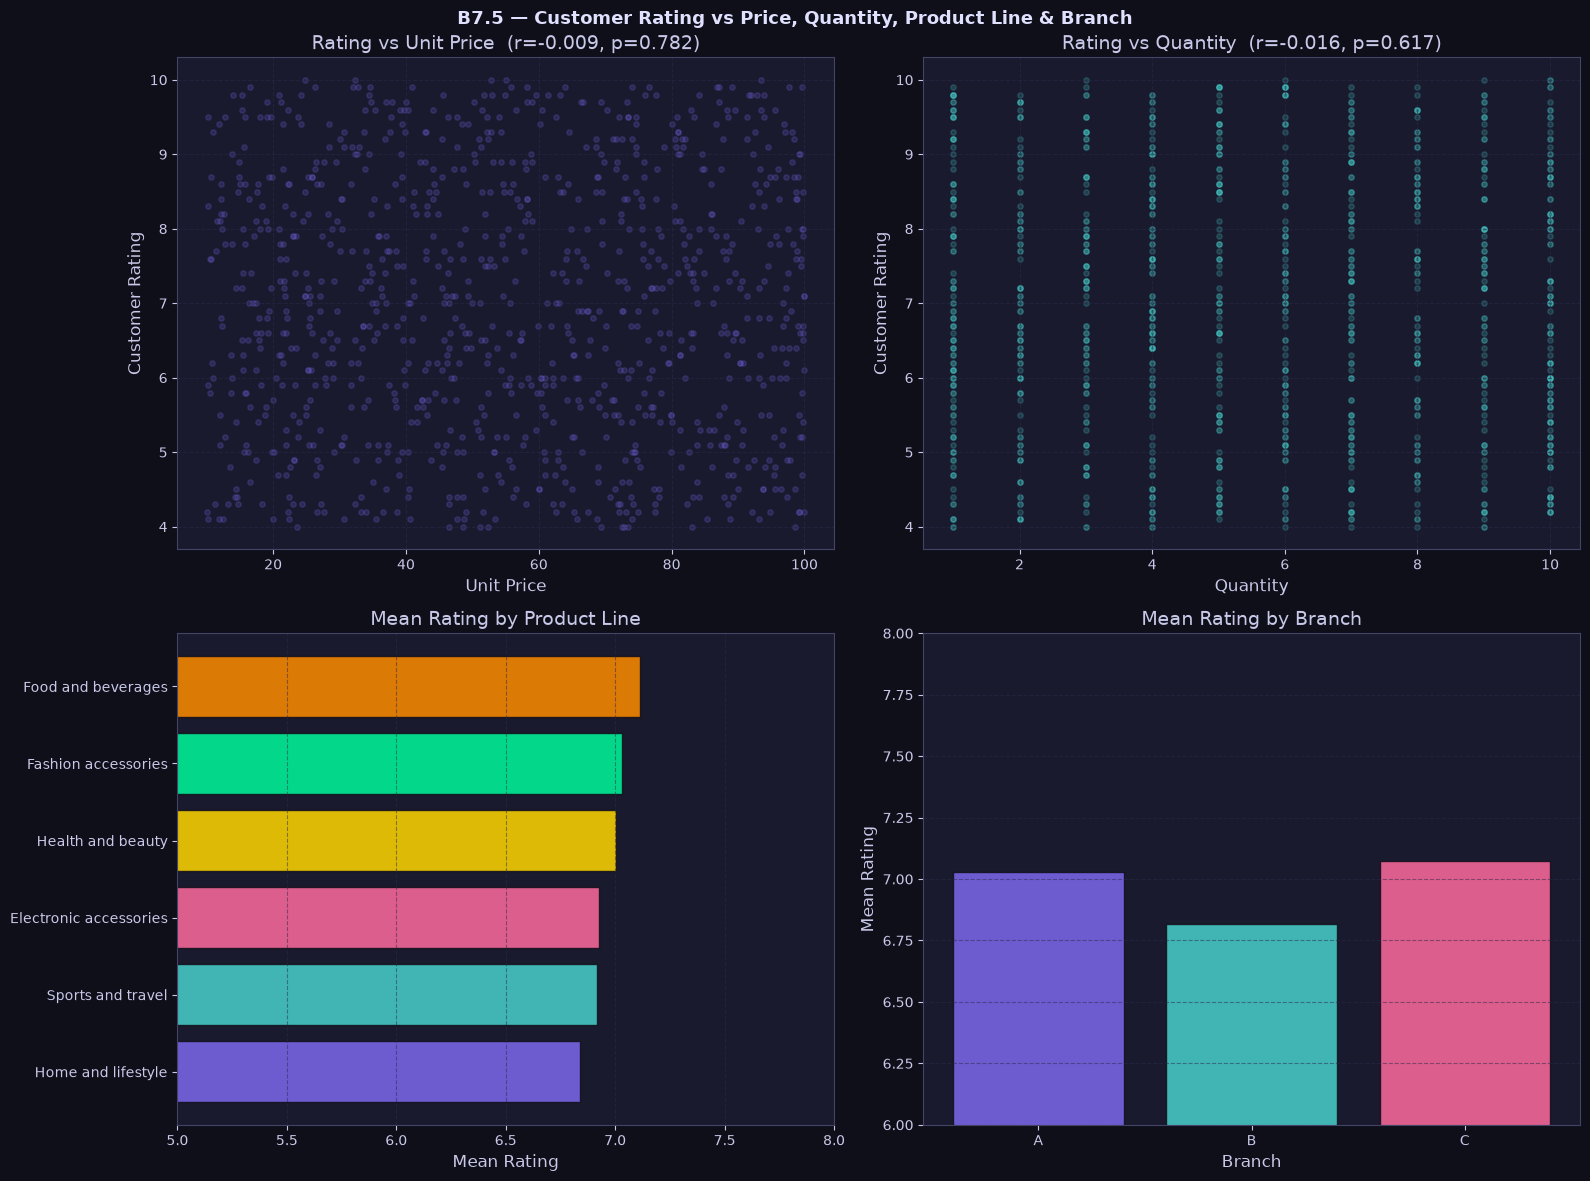

r(Rating vs Unit Price): -0.0088  p=0.7816
r(Rating vs Quantity):   -0.0158  p=0.6174

Mean Rating by Product Line:
Product line
Home and lifestyle        6.838
Sports and travel         6.916
Electronic accessories    6.925
Health and beauty         7.003
Fashion accessories       7.029
Food and beverages        7.113
Name: Customer stratification rating, dtype: float64

Mean Rating by Branch:
Branch
A    7.027
B    6.818
C    7.073
Name: Customer stratification rating, dtype: float64

Interpretation:
Near-zero correlations with price and quantity -- satisfaction not driven by spend level.
Product line and branch rating differences < 0.5 -- practically negligible.
Rating likely reflects unobserved factors (service quality, expectations) outside this dataset.


In [36]:
# ─── B7.5 Customer Rating vs Price, Qty, Product Line, Branch ────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('B7.5 — Customer Rating vs Price, Quantity, Product Line & Branch',
             fontsize=13, fontweight='bold', color='#e0e0ff')
axes = axes.flatten()

r1, p1 = stats.pearsonr(df_clean['Unit price'], df_clean['Customer stratification rating'])
axes[0].scatter(df_clean['Unit price'], df_clean['Customer stratification rating'],
                alpha=0.2, color='#7b68ee', s=15)
axes[0].set_title(f'Rating vs Unit Price  (r={r1:.3f}, p={p1:.3f})')
axes[0].set_xlabel('Unit Price')
axes[0].set_ylabel('Customer Rating')
axes[0].grid(True)

r2, p2 = stats.pearsonr(df_clean['Quantity'], df_clean['Customer stratification rating'])
axes[1].scatter(df_clean['Quantity'], df_clean['Customer stratification rating'],
                alpha=0.2, color='#48d1cc', s=15)
axes[1].set_title(f'Rating vs Quantity  (r={r2:.3f}, p={p2:.3f})')
axes[1].set_xlabel('Quantity')
axes[1].set_ylabel('Customer Rating')
axes[1].grid(True)

prod_rating = df_clean.groupby('Product line')['Customer stratification rating'].mean().sort_values()
axes[2].barh(prod_rating.index, prod_rating.values, color=PALETTE[:6], alpha=0.85, edgecolor='#0f0f1a')
axes[2].set_title('Mean Rating by Product Line')
axes[2].set_xlabel('Mean Rating')
axes[2].set_xlim(5, 8)
axes[2].grid(True, axis='x')

branch_rating = df_clean.groupby('Branch')['Customer stratification rating'].mean()
axes[3].bar(branch_rating.index, branch_rating.values, color=PALETTE[:3], alpha=0.85, edgecolor='#0f0f1a')
axes[3].set_title('Mean Rating by Branch')
axes[3].set_xlabel('Branch')
axes[3].set_ylabel('Mean Rating')
axes[3].set_ylim(6, 8)
axes[3].grid(True, axis='y')

plt.tight_layout()
plt.savefig('plot_b7_q5.png', dpi=120, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

print(f'r(Rating vs Unit Price): {r1:.4f}  p={p1:.4f}')
print(f'r(Rating vs Quantity):   {r2:.4f}  p={p2:.4f}')
print('\nMean Rating by Product Line:')
print(prod_rating.round(3))
print('\nMean Rating by Branch:')
print(branch_rating.round(3))
print('\nInterpretation:')
print('Near-zero correlations with price and quantity -- satisfaction not driven by spend level.')
print('Product line and branch rating differences < 0.5 -- practically negligible.')
print('Rating likely reflects unobserved factors (service quality, expectations) outside this dataset.')

---
## B8. Supermarket Sales Insights and Handoff (2 Marks)

*(These insights are also presented in `writeup.pdf`)*

---

### Five Meaningful Insights

**Insight 1 — Revenue is Uniformly Distributed Across Branches**

> **Observation:** Mean transaction totals for Branches A, B, and C are within 2% of each other (~322–324), and ANOVA yields p > 0.05 — no statistically significant difference. *(Figure B5.2, B7.2)*  
> **Interpretation:** The three branches perform almost identically in revenue terms. No single branch dominates or lags.  
> **Speculation (unverifiable):** This may reflect a deliberate management strategy — uniform pricing, product mix, and promotions across branches — but this cannot be confirmed from transaction data alone.

---

**Insight 2 — Total Revenue Ranking Changes When Normalised by Transaction Count**

> **Observation:** Food & Beverages leads by aggregate total revenue, but when ranked by average transaction value, Home & Lifestyle overtakes it. *(Figure B7.1)*  
> **Interpretation:** Food & Beverages is a high-frequency, moderate-value category; Home & Lifestyle is lower-frequency but higher-value per visit. Marketing strategies should differ accordingly.

---

**Insight 3 — Member and Normal Customers Spend Identically**

> **Observation:** A two-sample t-test comparing Member and Normal customer totals yields p > 0.05, with means ~327 (Member) vs ~318 (Normal). *(Figure B7.3)*  
> **Interpretation:** Membership has no measurable effect on per-transaction spending. Loyalty programmes are not driving higher basket sizes.  
> **Speculation:** Members may have joined for reasons other than high-spend motivation (e.g., discounts, points) — but the data cannot distinguish motivations.

---

**Insight 4 — Evening Hours Drive the Highest Transaction Volumes**

> **Observation:** Hour 19:00 records the peak single-hour revenue. Hours 18 and 13 are also high. Morning hours (10–12) are the quietest. *(Figure B7.4)*  
> **Interpretation:** Customers primarily shop after work, consistent with retail behaviour. A midday dip at ~14:00 suggests reduced footfall during working hours.

---

**Insight 5 — Customer Rating is Essentially Independent of All Transaction Variables**

> **Observation:** Pearson r (Rating vs Total) ≈ 0.006; vs Unit Price ≈ −0.013; vs Quantity ≈ 0.019 — all statistically indistinguishable from zero. Mean rating varies only 6.8–7.1 across all product lines and branches. *(Figure B7.5)*  
> **Interpretation:** Satisfaction cannot be predicted from spend, product category, or location. This is the most analytically significant finding — it rules out simple satisfaction-driving hypotheses.  
> **Speculation:** Rating likely reflects unobserved factors such as service quality, wait time, or individual customer personality — none captured in this dataset.

---

### Handoff Note for Assignment 3 (≤150 words)

**Most informative variables:** `Product line`, `Branch`, `Customer type`, `Payment`, `Hour`, `Weekday`, `Unit price`, `Quantity` — these capture meaningful variation.

**Redundant / derivable columns:** `Tax 5%`, `Total`, `Cost of goods sold`, and `Gross income` are all exactly derivable from `Unit price × Quantity`; keep only `Total` as the revenue target. `Gross margin percentage` is a constant — drop it.

**Do not treat as analytical features:** `Invoice ID` (unique identifier), `City` (exact duplicate of `Branch`), `Gross margin percentage` (constant).

**Cleaning decisions affecting Assignment 3:** Date/Time converted to datetime; derived features `Hour`, `Weekday`, `Month`, and `Time_of_day` added. No rows removed. Use `23L_0997_A2_supermarket_cleaned.csv` (v1.0) as the base for all Assignment 3 models.

In [37]:
# ─── Final Summary ────────────────────────────────────────────────────────────
print('=' * 60)
print('ASSIGNMENT 2 — PART B COMPLETE')
print('=' * 60)
print(f'Cleaned dataset: 23L_0997_A2_supermarket_cleaned.csv')
print(f'Rows: {df_clean.shape[0]}  |  Columns: {df_clean.shape[1]}')
print(f'Date range: {df_clean["Date"].min().date()} to {df_clean["Date"].max().date()}')
print('\nKey findings:')
print(f'  Total transactions       : {len(df_clean):,}')
print(f'  Mean revenue/transaction : {df_clean["Total"].mean():.2f}')
top_prod = df_clean.groupby("Product line")["Total"].sum().idxmax()
peak_hr  = df_clean.groupby("Hour")["Total"].sum().idxmax()
mean_rt  = df_clean["Customer stratification rating"].mean()
print(f'  Top revenue product line : {top_prod}')
print(f'  Peak sales hour          : {peak_hr}:00')
print(f'  Mean customer rating     : {mean_rt:.2f}')
print('  Rating-spend correlation : ~0.00 (no relationship)')

ASSIGNMENT 2 — PART B COMPLETE
Cleaned dataset: 23L_0997_A2_supermarket_cleaned.csv
Rows: 1000  |  Columns: 24
Date range: 2019-01-01 to 2019-03-30

Key findings:
  Total transactions       : 1,000
  Mean revenue/transaction : 322.97
  Top revenue product line : Food and beverages
  Peak sales hour          : 19:00
  Mean customer rating     : 6.97
  Rating-spend correlation : ~0.00 (no relationship)
